# Tensor networks and matrix-product states


This notebook shows how tensor-networks can be used to represent quantum wavefunctions.
In particular, we will introduce matrix-product states, which are one of the most effective
ways of simulating one-dimensional quantum systems.


In [1]:
import importlib.util
import subprocess
import sys

# Install missing packages into this notebook's own Python environment.
packages = {"numpy": "numpy", "PIL": "pillow", "ipywidgets": "ipywidgets"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    importlib.invalidate_caches()
print("Notebook dependencies are ready. Continue with the next cell.")

Notebook dependencies are ready. Continue with the next cell.


In [2]:
import numpy as np

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(7)

## 1. Wavefunctions as tensors

For a system of $N$ sites, a general pure state can be written as

$$
|\psi\rangle = \sum_{s_1,\ldots,s_N} C_{s_1\cdots s_N}
|s_1\rangle\otimes\cdots\otimes|s_N\rangle,
$$

where $s_i$ labels a basis state at site $i$. These site labels do not assume any particular
spatial geometry.

We usually think of the coefficients $C_{s_1\cdots s_N}$ as the entries of a single vector in
the many-body Hilbert space. Alternatively, we can view them as an $N$-dimensional array, with
$d$ entries along each axis, which we call a **tensor**. It's important to remember this is
just a different way of organizing the same coefficients.

For the examples, each site has two basis states, $|0\rangle$ and $|1\rangle$, so $d=2$.
Four sites have $2^4=16$ coefficients. NumPy can store them as either a length-16 vector or
an array of shape `(2, 2, 2, 2)`.

In [3]:
# A normalized four-site state. No spatial arrangement is assumed here.
psi = rng.normal(size=16) + 1j * rng.normal(size=16)
psi /= np.linalg.norm(psi)
C = psi.reshape(2, 2, 2, 2)

configuration = (0, 1, 0, 1)
flat_index = np.ravel_multi_index(configuration, C.shape)
print("Vector shape:", psi.shape)
print("Tensor shape:", C.shape)
print("Coefficient C[0, 1, 0, 1]:", C[configuration])
print("Same vector entry:", psi[flat_index])

Vector shape: (16,)
Tensor shape: (2, 2, 2, 2)
Coefficient C[0, 1, 0, 1]: (-0.1874274385521283-0.044433703018115514j)
Same vector entry: (-0.1874274385521283-0.044433703018115514j)


## 2. Tensor diagrams and contraction
A **tensor network** is simply a decomposition of $C$ into smaller tensors. Just as matrices
can be multiplied to produce new matrices, tensors can be **contracted** to produce new
tensors. In a tensor-network representation of a wavefunction, various tensors are contracted
to produce $C$.

Writing these tensor contractions explicitly can quickly become cumbersome, so a helpful
diagrammatic notation makes the tensors and their manipulations easier to see.

In a tensor-network diagram, tensors are represented as nodes with a number of legs sticking
out, each of the legs representing an individual index of the tensor. A scalar has no indices,
a vector has one, and a matrix has two. 

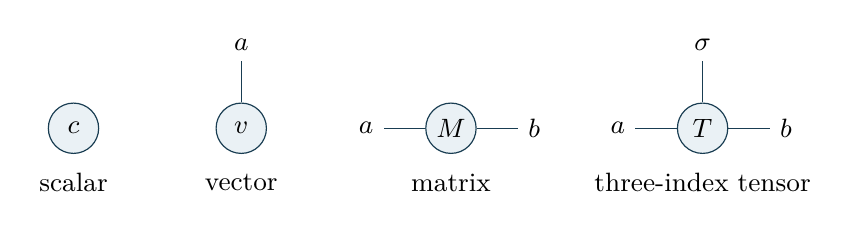


### Matrix multiplication

Tensor contraction is summing over shared indices to produce new tensors. For example,
multiplying two matrices $A$ and $B$ to produce a new matrix $C$ can be written as follows.

| Contraction | Tensor diagram |
| :--- | :--- |
| $C_{ac}=\sum_b A_{ab}B_{bc}$ | 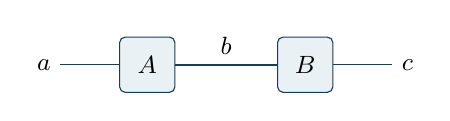 |

In a tensor-network diagram this is depicted as a two-leg $A$ tensor with one of its legs
connected to a two-leg $B$ tensor, producing an overall two-leg object, $C$.

We will use NumPy's **einsum** function: https://numpy.org/doc/stable/reference/generated/numpy.einsum.html .
einsum works by performing an Einstein summation on a list of tensors. You input the list of tensors and also the subscripts where repeated subscripts are summed over. This can sound a little confusing but we'll see some examples below: 


In [4]:
A = rng.normal(size=(2, 12))
B = rng.normal(size=(12, 2))
C_matrix = np.einsum("ab,bc->ac", A, B)
print(A.shape, "contracted with", B.shape, "gives", C_matrix.shape)

(2, 12) contracted with (12, 2) gives (2, 2)


### Taking a trace

For a square matrix $C$, we can join its ingoing and outgoing legs. This identifies the two
indices and sums over them, giving the **trace**. No open legs remain, so the result is a
**scalar**. The two legs must have the same dimension; we chose $C$ to be square in the example
above.

| Contraction | Tensor diagram |
| :--- | :--- |
| $\operatorname{tr}(C)=\sum_a C_{aa}$ | 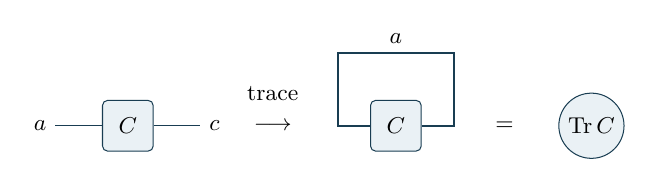 |

In [5]:
# The repeated index is summed; no output indices means a scalar.
trace_C = np.einsum("aa->", C_matrix)
print("trace(C) =", trace_C)
print("Shape:", trace_C.shape)

trace(C) = 8.051996905212036
Shape: ()


### Contracting two three-leg tensors

Of course, it would be total overkill to introduce a whole new graphical notation to just do
matrix-matrix and matrix-vector multiplication, so let's think about contracting one leg of
two three-leg tensors $D$ and $E$.

| Contraction | Tensor diagram |
| :--- | :--- |
| $F_{abcd}=\sum_x D_{abx}E_{xcd}$ | 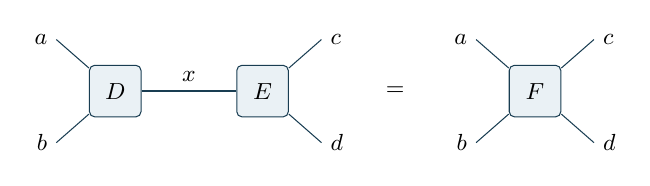 |

Since four legs of $D$ and $E$ remain uncontracted this produces $F$, a four-leg tensor.

In [6]:
D = rng.normal(size=(2, 3, 5))
E = rng.normal(size=(5, 4, 2))
F=np.einsum("abx,xcd->abcd",D,E)
print("F has shape", F.shape)

F has shape (2, 3, 4, 2)


In [7]:
X = rng.normal(size=(2,3,4,5,6))
Y = rng.normal(size=(5,10,6,2,3,4))
Z = np.einsum("abcxy,xdyefg->bacdegf", X, Y)
print("Z has shape", Z.shape)

Z has shape (3, 2, 4, 10, 2, 4, 3)


### Reshaping a contraction into matrix multiplication

In practice, how do we actually do tensor contractions on a computer? In this notebook we use einsum which does tensor contractions explicitly, but what is really happening?

We are always free to reshape tensors by **grouping (fusing)** legs to create a larger leg whose dimension is the product of all the
fused legs. Similarly, we can **separate (split)** one leg into several smaller legs, provided
the product of the dimensions matches the original leg.

For each tensor, group together the legs to be contracted and, separately, the uncontracted
legs. The tensor contraction is then simply matrix multiplication. In this example, group
$(a,b)$ into a row index and $(c,d)$ into a column index.

In [8]:
D_matrix = D.reshape(2 * 3, 5)
E_matrix = E.reshape(5, 4 * 2)
F_from_matrices = (D_matrix @ E_matrix).reshape(2, 3, 4, 2)

print("The matrix and tensor contractions agree:", np.allclose(F, F_from_matrices))

The matrix and tensor contractions agree: True


If the legs you want to group are not next to one another, or not in the correct order, use `transpose` to put them in the
required order **before** reshaping. `reshape` doesn't permute the indices.


### Contraction order matters

An important detail to remember when performing tensor contraction is that the cost can depend
upon the order in which we contract. Consider the three-tensor network

$$T_{pq}=\sum_{a,b,c}X_{ab}Y_{apc}Z_{bcq}.$$

For this example, every index has dimension $\chi$, including the open indices $p$ and $q$.
We use `bond_dim` to vary $\chi$ in the experiment below.

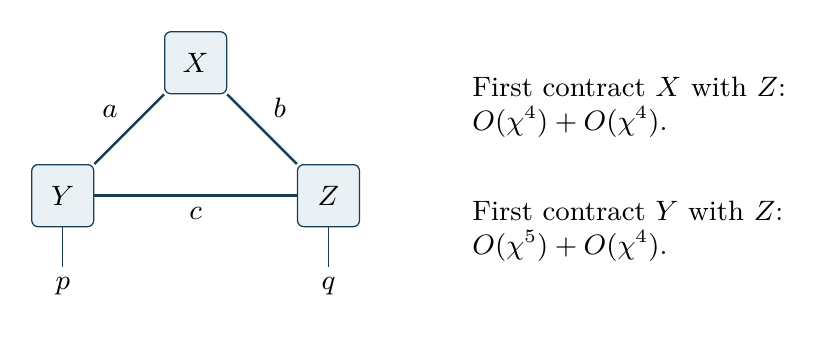


Contracting $X$ and $Z$ first gives

$$K_{acq}=\sum_b X_{ab}Z_{bcq},\qquad
T_{pq}=\sum_{a,c}Y_{apc}K_{acq}.$$

Both steps cost $O(\chi^4)$ with ordinary dense contractions, and the largest intermediate
has $\chi^3$ entries. Contracting $Y$ and $Z$ first instead produces

$$Q_{apbq}=\sum_c Y_{apc}Z_{bcq},\qquad
T_{pq}=\sum_{a,b}X_{ab}Q_{apbq}.$$

The first step costs $O(\chi^5)$ and stores $\chi^4$ entries; the final step costs $O(\chi^4)$.
Despite producing the same result, this contraction order is significantly less efficient
as $\chi$ grows. Doubling $\chi$ multiplies the intermediate sizes by 8 and 16 respectively.

We write each pairwise contraction separately and leave `optimize=False` (the default) so NumPy follows
exactly the specified route. In a single three-input `einsum`, an optimizer could choose the
efficient order for us and hide the comparison.

In [9]:
from timeit import repeat


def good_order(X, Y, Z):
    K = np.einsum("ab,bcq->acq", X, Z)
    return np.einsum("apc,acq->pq", Y, K)


def bad_order(X, Y, Z):
    Q = np.einsum("apc,bcq->apbq", Y, Z)
    return np.einsum("ab,apbq->pq", X, Q)


def median_seconds(function, repeats=5):
    function()  # Warm up before timing three calls per sample.
    return np.median(repeat(function, repeat=repeats, number=3)) / 3

Set `bond_dim = 32` initially. The cell times that size and two smaller ones;
then try a different value, such as 24 or 48. The $\chi^4$ intermediate grows quickly.

In [10]:
bond_dim = 64  # Change this to explore the scaling.
repeats = 5
sizes = [bond_dim // 4, bond_dim // 2, bond_dim]

print(f"{'chi':>5} {'good (ms)':>12} {'bad (ms)':>12} {'bad/good':>12}"
      f" {'K (MiB)':>12} {'Q (MiB)':>12}")
for chi in sizes:
    X = rng.normal(size=(chi, chi))
    Y = rng.normal(size=(chi, chi, chi))
    Z = rng.normal(size=(chi, chi, chi))
    good_s = median_seconds(lambda: good_order(X, Y, Z), repeats)
    bad_s = median_seconds(lambda: bad_order(X, Y, Z), repeats)
    K_mib = chi**3 * X.itemsize / 2**20
    Q_mib = chi**4 * X.itemsize / 2**20
    print(f"{chi:>5} {1000*good_s:>12.3f} {1000*bad_s:>12.3f}"
          f" {bad_s/good_s:>11.1f}x {K_mib:>12.3f} {Q_mib:>12.3f}")

  chi    good (ms)     bad (ms)     bad/good      K (MiB)      Q (MiB)
   16        0.080        0.409         5.1x        0.031        0.500


   32        0.365        8.478        23.2x        0.250        8.000


   64        4.801      187.701        39.1x        2.000      128.000


The extra open legs of the bad intermediate are the source of the extra work and storage.
The lesson is to inspect intermediate tensors, rather than just the final answer. This will
matter again when contracting an MPS: a suitable order keeps the intermediate tensors small.

## 3. Matrix-product states

We can now return to representing quantum many-body wavefunctions in terms of tensor networks,
by choosing a representation of the $N$-leg tensor $C$ in terms of smaller tensors. While we're
free to choose any graph we like, typically we want to choose a regular structure for
theoretical and numerical reasons.

The simplest choice is a **matrix-product state (MPS)**: a chain of three-leg tensors, with
two legs contracted to the left and right, and one free leg corresponding to a free leg of
$C$. For open boundaries the chain is terminated by a two-leg tensor at each end. We can also
keep the same three-axis array convention everywhere by giving the outer virtual legs
dimension one.

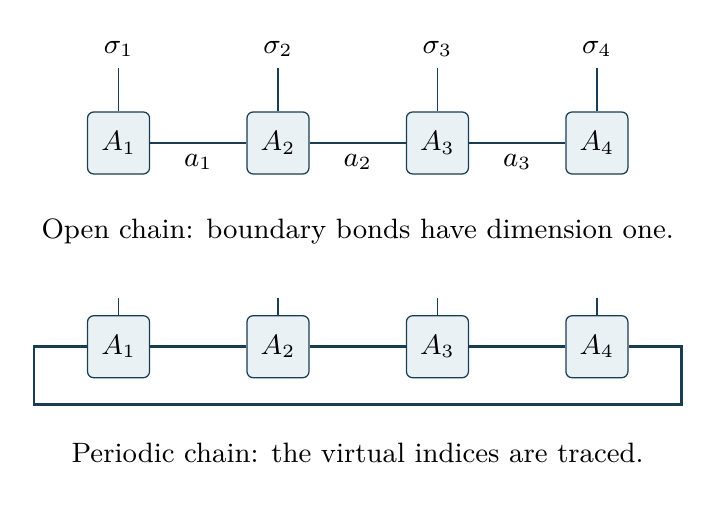

A particular coefficient of the wavefunction is found by fixing the physical legs of the
three-leg tensors, and then taking the product of $N$ matrices. An open-boundary MPS can be
written as

$$
|\psi\rangle=\sum_{s_1,\ldots,s_N}
A_1^{s_1}A_2^{s_2}\cdots A_N^{s_N}|s_1\cdots s_N\rangle.
$$

Here $A_i^{s_i}$ is a $\chi_{i-1}\times\chi_i$ matrix and $\chi_0=\chi_N=1$.
Each internal index has a dimension, called its
**bond dimension**. These dimensions determine the number of coefficients stored in the tensors
and constrain the **entanglement** the network can represent.

The diagram labels physical legs $\sigma_i$; these are the same indices called $s_i$ here.

In NumPy, use one array per site with axes **(physical, left virtual, right virtual)**:
`mps[i].shape == (d, chi_left, chi_right)`. Selecting `mps[i][s]` leaves a matrix.
The functions below either select one coefficient or contract the full small example.

In [11]:
def mps_coefficient(mps, configuration):
    value = np.ones(1)
    for tensor, s in zip(mps, configuration):
        value = np.einsum("a,ab->b", value, tensor[s])
    return value.item()


def mps_to_tensor(mps):
    result = np.ones(1)
    for tensor in mps:
        result = np.einsum("...a,sab->...sb", result, tensor)
    return result[..., 0]


# The product state |0101>: all virtual dimensions are one.
local_states = [np.array([1., 0.]), np.array([0., 1.])] * 2
product_mps = [v.reshape(2, 1, 1) for v in local_states]
print("Site tensor shapes:", [a.shape for a in product_mps])
print("Coefficient of |0101>:", mps_coefficient(product_mps, (0, 1, 0, 1)))
print("Coefficient of |0000>:", mps_coefficient(product_mps, (0, 0, 0, 0)))

Site tensor shapes: [(2, 1, 1), (2, 1, 1), (2, 1, 1), (2, 1, 1)]
Coefficient of |0101>: 1.0
Coefficient of |0000>: 0.0


### Other network geometries

The figure below, reused from the notes, shows how a different choice of graph leads to tree
tensor networks or PEPS. Each open leg still represents a physical index, and each internal
leg is a summed virtual index.

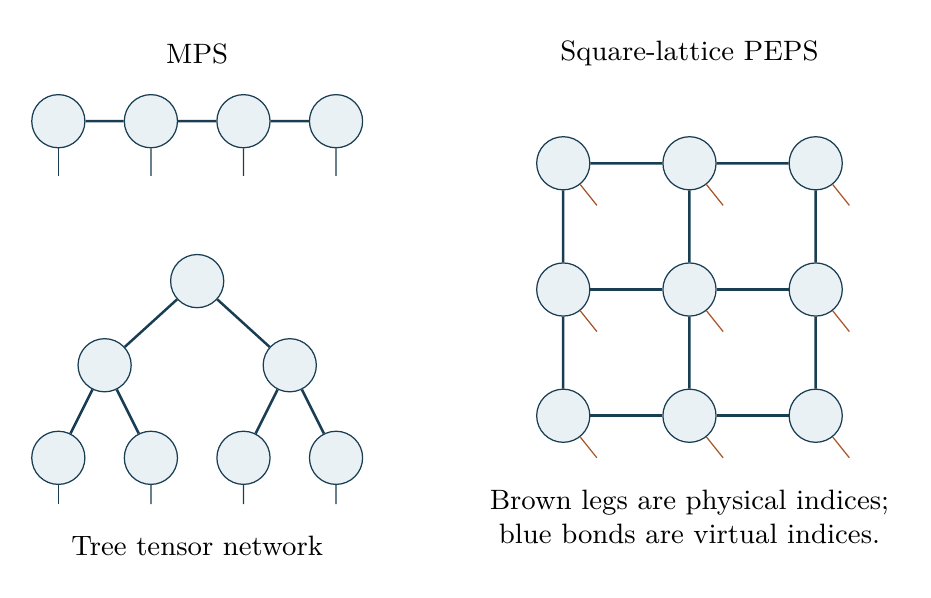


### The GHZ state as a simple MPS

Consider the six-site GHZ state

$$|\mathrm{GHZ}\rangle=\frac{|000000\rangle+|111111\rangle}{\sqrt2}.$$

This can be represented as a bond dimension $\chi=2$ MPS for any system size. The two **bulk matrices**, used at sites $2,\ldots,N-1$, are

$$
A^0=\begin{pmatrix}1&0\\0&0\end{pmatrix},\qquad
A^1=\begin{pmatrix}0&0\\0&1\end{pmatrix}.
$$

They satisfy $A^0A^1=A^1A^0=0$ and $(A^s)^2=A^s$. Therefore any coefficient of the wavefunction with a mixture of 0s and 1s will
vanish, only the all 0s and all 1s components survive.

To specify the open ends, take the row and column vectors

$$
\ell=\frac{1}{\sqrt2}\begin{pmatrix}1&1\end{pmatrix},\qquad
r=\begin{pmatrix}1\\1\end{pmatrix},\qquad
C_{s_1\cdots s_N}=\ell A^{s_1}\cdots A^{s_N}r.
$$

Absorbing these vectors into the end tensors gives $A_1^s=\ell A^s$ and $A_N^s=A^s r$.
These are a $1\times2$ row and a $2\times1$ column, respectively, so they match the array
convention above. The code writes out the bulk matrices explicitly and constructs the ends
from these boundary vectors.


In [12]:
def ghz_mps(n_sites):
    # bulk[s] is the matrix A^s selected by the physical index s.
    bulk = np.array([[[1., 0.], [0., 0.]],
                     [[0., 0.], [0., 1.]]])
    left = np.array([1., 1.]) / np.sqrt(2)
    right = np.array([1., 1.])
    first = np.einsum("a,sab->sb", left, bulk)[:, None, :]
    last = np.einsum("sab,b->sa", bulk, right)[:, :, None]
    return [first] + [bulk.copy() for _ in range(n_sites - 2)] + [last]


n_sites = 6  # Choose at least two sites.
ghz = ghz_mps(n_sites)
C_ghz = mps_to_tensor(ghz)
print("Site tensor shapes:", [a.shape for a in ghz])
for configuration in [(0,) * n_sites, (1,) * n_sites, tuple(i % 2 for i in range(n_sites))]:
    print(configuration, "->", mps_coefficient(ghz, configuration))

Site tensor shapes: [(2, 1, 2), (2, 2, 2), (2, 2, 2), (2, 2, 2), (2, 2, 2), (2, 2, 1)]
(0, 0, 0, 0, 0, 0) -> 0.7071067811865475
(1, 1, 1, 1, 1, 1) -> 0.7071067811865475
(0, 1, 0, 1, 0, 1) -> 0.0


## 4. Turning a state into an MPS

We will now show that any finite pure state can be represented as an MPS, provided the bond
dimension is big enough. We will do this by applying the **singular value decomposition (SVD)**
repeatedly across the system.

For a matrix, NumPy's SVD returns

$$M=U\,S\,V^\dagger.$$

$S=\text{diag}(s_1,s_2,...)$ is a diagonal matrix. The singular values $s_a$ are nonnegative and ordered from largest to smallest. The largest singular values give you
the most information about the matrix, whereas smaller singular values contribute less. The number of non-zero singular values is called the **rank** of a matrix. The columns
of $U$ and the rows of $V^\dagger$ are orthonormal, they will be unitary matrices for a square input matrix. `np.linalg.svd` returns `U, s, Vh`, where
`Vh` is $V^\dagger$. `full_matrices=False` avoids the unused extra rows and columns.

### First site

First reshape the coefficient tensor as $C_{s_1,[s_2\cdots s_N]}$, separating the first leg
from all the others, which are grouped together, and take its SVD. 

$$C_{s_1,[s_2\cdots s_N]}= \sum_{a_1,a_2} U_{s_1,a_1} S_{a_1,a_2} (V^\dagger)_{a_2,[s_2\cdots s_N]}$$

We begin to define an MPS by turning $U=A_1$ into the the first tensor, with $a_1$ labelling the first virtual leg. $SV^\dagger=\widetilde C_{a_1s_2\cdots s_N}$ defines the remaining coefficient tensor:

$$C_{s_1\cdots s_N}=\sum_{a_1}(A_1^{s_1})_{1a_1}
\widetilde C_{a_1s_2\cdots s_N}.$$

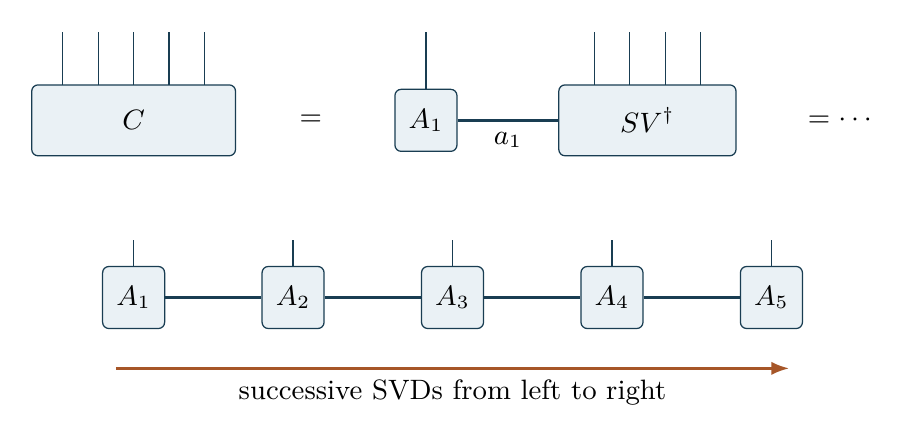


In [13]:
U1, s1, Vh1 = np.linalg.svd(C_ghz.reshape(2, -1), full_matrices=False)
A1 = U1.reshape(2, 1, len(s1))
remainder1 = np.einsum("a,ab->ab", s1, Vh1)

print("First singular values:", s1)
print("First site tensor:", A1.shape)
print("Remaining tensor, still grouped:", remainder1.shape)

First singular values: [0.7071 0.7071]
First site tensor: (2, 1, 2)
Remaining tensor, still grouped: (2, 32)


### Second site

For the second site, reshape the remaining tensor into a matrix with $(a_1,s_2)$ as its row
index and $(s_3,\ldots,s_N)$ as its column index. Taking its SVD gives another $U$, which we
reshape into the second site tensor, and a new remaining tensor:

$$\widetilde C_{[a_1s_2],[s_3\cdots s_N]}=(U_2S_2V_2^\dagger)_{[a_1s_2],[s_3\cdots s_N]}.$$

$$C_{s_1\cdots s_N}=\sum_{a_1,a_2}(A_1^{s_1})_{1a_1}
(A_2^{s_2})_{a_1a_2}\widetilde C^{(2)}_{a_2s_3\cdots s_N}.$$

Notice the `transpose`: the SVD groups the axes as `(left virtual, physical, right virtual)`.
We reorder them to our `(physical, left virtual, right virtual)` convention.

In [14]:
chi1 = A1.shape[2]
U2, s2, Vh2 = np.linalg.svd(remainder1.reshape(chi1 * 2, -1), full_matrices=False)
# Drop numerical zeros; their exact mathematical values are zero for GHZ.
chi2 = np.count_nonzero(s2 > 1e-12 * s2[0])
A2 = U2[:, :chi2].reshape(chi1, 2, chi2).transpose(1, 0, 2)
remainder2 = np.einsum("a,ab->ab", s2[:chi2], Vh2[:chi2])

print("Second singular values:", s2)
print("Second site tensor:", A2.shape)
print("Remaining tensor:", remainder2.shape)

Second singular values: [0.7071 0.7071 0.     0.    ]
Second site tensor: (2, 2, 2)
Remaining tensor: (2, 16)


By repeating this process until only the final site remains we transform the state into an
MPS. At each step, reshape $U$ into a site tensor with one physical and two virtual indices,
and pass the remaining factor to the next site.

Here is the complete sweep. Read the loop and match its operations to the two steps above;
you do not need to write it from scratch. `cutoff` sets a numerical threshold relative to
the largest singular value at each step; unlike the exact mathematical construction, it
can discard very small nonzero values. `max_bond` will let us deliberately compress the
state in the final part.

In [15]:
def tensor_to_mps(tensor, max_bond=None, cutoff=1e-12):
    """Left-to-right SVD; arrays use (physical, left virtual, right virtual)."""
    dims = tensor.shape
    remainder = tensor
    chi_left = 1
    mps = []
    for d in dims[:-1]:
        matrix = remainder.reshape(chi_left * d, -1)
        U, s, Vh = np.linalg.svd(matrix, full_matrices=False)
        keep = max(1, np.count_nonzero(s > cutoff * s[0]))
        if max_bond is not None:
            keep = min(keep, max_bond)
        site = U[:, :keep].reshape(chi_left, d, keep).transpose(1, 0, 2)
        mps.append(site)
        remainder = np.einsum("a,ab->ab", s[:keep], Vh[:keep])
        chi_left = keep
    last = remainder.reshape(chi_left, dims[-1], 1).transpose(1, 0, 2)
    mps.append(last)
    return mps


ghz_from_svd = tensor_to_mps(C_ghz)
print("Bonds from SVD:", [a.shape[2] for a in ghz_from_svd[:-1]])
print("Reconstruction error:", np.linalg.norm(C_ghz - mps_to_tensor(ghz_from_svd)))

Bonds from SVD: [2, 2, 2, 2, 2]
Reconstruction error: 0.0


The SVD tensors need not be identical to the hand-written GHZ tensors. They give the same
coefficient tensor when contracted: an MPS representation is not unique.


In [16]:
C_random = rng.normal(size=(2,) * 6) + 1j * rng.normal(size=(2,) * 6)
C_random /= np.linalg.norm(C_random)
random_mps = tensor_to_mps(C_random)

print("Random-state bonds:", [a.shape[2] for a in random_mps[:-1]])
print("Reconstruction error:", np.linalg.norm(C_random - mps_to_tensor(random_mps)))

Random-state bonds: [2, 4, 8, 4, 2]
Reconstruction error: 1.4561052239826857e-15


## 5. Bond dimension and compression

How large must these bonds be for an arbitrary state? At the cut after site $n$, the left
and right Hilbert spaces have dimensions $d^n$ and $d^{N-n}$. The matrix rank cannot exceed
either dimension, so an exact MPS can be constructed with

$$\chi_n\leq\min(d^n,d^{N-n})=d^{\min(n,N-n)}.$$

This means the largest bond dimension can be **exponential** in the system size! 
In fact, a random wavefunction saturates these bounds. This means that while every finite pure state therefore has an exact MPS representation, they will often not be useful.

The cost of storing an MPS is

$$\sum_i d\chi_{i-1}\chi_i=O(Nd\chi^2)$$

for bounded $\chi$. This is linear in $N$ provided that we can represent the state we want
at a fixed bond dimension. An exact MPS of a generic small state can even store **more**
coefficients than its full coefficient tensor.

An MPS representation of a state can be efficient if we can ignore small singular values as we're sweeping through the system. We saw one example of this being possible with the GHZ state, but what justification can we have for doing this more generally?

In [17]:
def stored_coefficients(mps):
    return sum(a.size for a in mps)


C_product = np.zeros((2,) * 6)
C_product[(0,) * 6] = 1
print(f"{'state':<12} {'dense':>8} {'MPS':>8}   bonds")
for name, tensor in [("product", C_product), ("GHZ", C_ghz), ("random", C_random)]:
    tensors = tensor_to_mps(tensor)
    bonds = [a.shape[2] for a in tensors[:-1]]
    print(f"{name:<12} {tensor.size:>8} {stored_coefficients(tensors):>8}   {bonds}")

state           dense      MPS   bonds
product            64       12   [1, 1, 1, 1, 1]
GHZ                64       40   [2, 2, 2, 2, 2]
random             64      168   [2, 4, 8, 4, 2]


### SVD truncation: compress a photograph

We can use SVD to compress a large and complex matrix using a **low-rank approximation**. In a low-rank approximation small singular values are set to zero to produce a simplified representation of the input matrix.
A grayscale image provides a visual example: its pixel intensities form a matrix $I$.
Writing $I=USV^\dagger$, we retain only the largest $k$ singular values to obtain

$$I_k=U_{[:,1:k]}\,\mathrm{diag}(s_1,\ldots,s_k)\,V^\dagger_{[1:k,:]}.$$

What does discarding singular values actually do? Use the portrait from the notes to find out.
The image has been resized, preserving its proportions, to 320 rows and 256 columns. We compute
its SVD once; moving the slider only reconstructs the image from the first $k$ components.

Run the collapsed image-data cell below once, it embeds the supplied portrait in the notebook.

In [18]:
import base64

# Embedded image data; no download or external file is needed.
portrait_png = base64.b64decode('...')

In [19]:
from io import BytesIO
from PIL import Image
from IPython.display import HTML, display
import ipywidgets as widgets

image_array = np.asarray(Image.open(BytesIO(portrait_png)).convert("L"), dtype=float) / 255
image_U, image_s, image_Vh = np.linalg.svd(image_array, full_matrices=False)
image_rows, image_cols = image_array.shape
print("Image matrix shape:", image_array.shape)
print("Number of singular values:", len(image_s))


def image_at_rank(k):
    return np.einsum("ik,k,kj->ij", image_U[:, :k], image_s[:k], image_Vh[:k])

Image matrix shape: (320, 256)
Number of singular values: 256


The next collapsed cell provides the display code. Run it, then run the slider cell beneath it.
The SVD itself and the low-rank reconstruction are the operations shown above.

In [20]:
def image_comparison_html(k):
    approximation = image_at_rank(k)
    # Metrics use the unclipped reconstruction, not the displayed 8-bit image.
    relative_error = np.linalg.norm(image_array - approximation) / np.linalg.norm(image_array)
    factor_entries = k * (image_rows + image_cols + 1)
    original_entries = image_array.size

    def png_data_uri(array):
        pixels = np.rint(255 * np.clip(array, 0, 1)).astype(np.uint8)
        buffer = BytesIO()
        Image.fromarray(pixels).save(buffer, format="PNG")
        return "data:image/png;base64," + base64.b64encode(buffer.getvalue()).decode("ascii")

    original_uri = "data:image/png;base64," + base64.b64encode(portrait_png).decode("ascii")
    reconstructed_uri = png_data_uri(approximation)
    panels = (f'<div style="display:flex;gap:20px;flex-wrap:wrap;max-width:720px">'
              f'<figure style="margin:0"><figcaption>Original image</figcaption>'
              f'<img src="{original_uri}" alt="Original portrait" width="256" height="320"></figure>'
              f'<figure style="margin:0"><figcaption>Rank {k}</figcaption>'
              f'<img src="{reconstructed_uri}" alt="Rank-{k} reconstruction" '
              f'width="256" height="320"></figure></div>')
    metrics = (f'<p><strong>Rank:</strong> {k} / {len(image_s)} &nbsp; '
               f'<strong>Relative pixel error:</strong> {relative_error:.2%}<br>'
               f'<strong>Factor entries:</strong> {factor_entries:,} / {original_entries:,} '
               f'({factor_entries / original_entries:.1%} of the original entry count)</p>')
    return panels + metrics


def show_image_rank(k):
    # Fallback for a notebook frontend that cannot display widget controls.
    display(HTML(image_comparison_html(k)))

IntSlider(value=10, continuous_update=False, description='Rank k:', max=141, min=1)


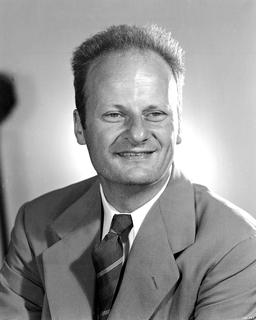
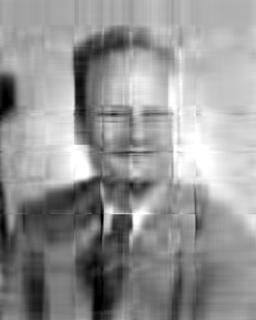

In [21]:
# Keep the factor-entry count at or below the original image's entry count.
max_compression_rank = min(len(image_s),
                           image_array.size // (image_rows + image_cols + 1))
rank_slider = widgets.IntSlider(value=min(10, max_compression_rank), min=1,
                                max=max_compression_rank, step=1,
                                description="Rank k:", continuous_update=False)
display(rank_slider)
image_view = display(HTML(image_comparison_html(rank_slider.value)), display_id=True)


def update_image_rank(change):
    image_view.update(HTML(image_comparison_html(change["new"])))


rank_slider.observe(update_image_rank, names="value")

### Keeping only the largest singular values

The slider kept the largest singular values and discarded the rest. Keeping only the
largest $k$ gives the best rank-$k$ approximation to the image matrix. Its squared error is

$$\|I-I_k\|_F^2=\sum_{a>k}s_a^2.$$

In an MPS sweep we apply exactly this idea at each bond: keeping only $\chi$ singular
values limits that bond dimension to $\chi$. 

Run the comparison below, then set `target = C_ghz` and run it again. The **fidelity** compares
the normalized original and reconstructed states and equals one when they agree up to a
phase. The error column uses the unnormalized reconstruction, so it also detects lost norm.

In [22]:
target = C_random  # Try C_ghz or C_product next.
print(f"{'max bond':>8} {'stored':>8} {'state error':>14} {'fidelity':>12}")
for chi in (1, 2, 4, 8):
    tensors = tensor_to_mps(target, max_bond=chi)
    approximation = mps_to_tensor(tensors)
    error = np.linalg.norm(target - approximation)
    fidelity = abs(np.einsum("i,i->", target.ravel().conj(), approximation.ravel())) ** 2
    fidelity /= (np.linalg.norm(target) * np.linalg.norm(approximation)) ** 2
    print(f"{chi:>8} {stored_coefficients(tensors):>8} {error:>14.6f} {fidelity:>12.6f}")

max bond   stored    state error     fidelity
       1       12       0.951951     0.093789
       2       40       0.752339     0.433986
       4      104       0.373379     0.860588
       8      168       0.000000     1.000000


## 6. Calculating the norm

We have seen how an MPS represents a wavefunction. We will now discuss how to calculate properties of the wavefunction efficiently using the MPS representation. The core idea is to think about the **order** in which you perform the contractions. The simplest possible calculation is calculating the **norm** of the wavefunction. Once this has been understood, other calculations become much more transparent. 

### The norm: contract one site at a time

The squared norm is $\mathcal N=\langle\psi|\psi\rangle$. Its tensor network has two
layers: the MPS and its complex conjugate, with each physical leg joined to the corresponding
leg in the other layer. Since all of the virtual legs and all of the physical legs have been contracted, the output is a scalar, the squared norm! 

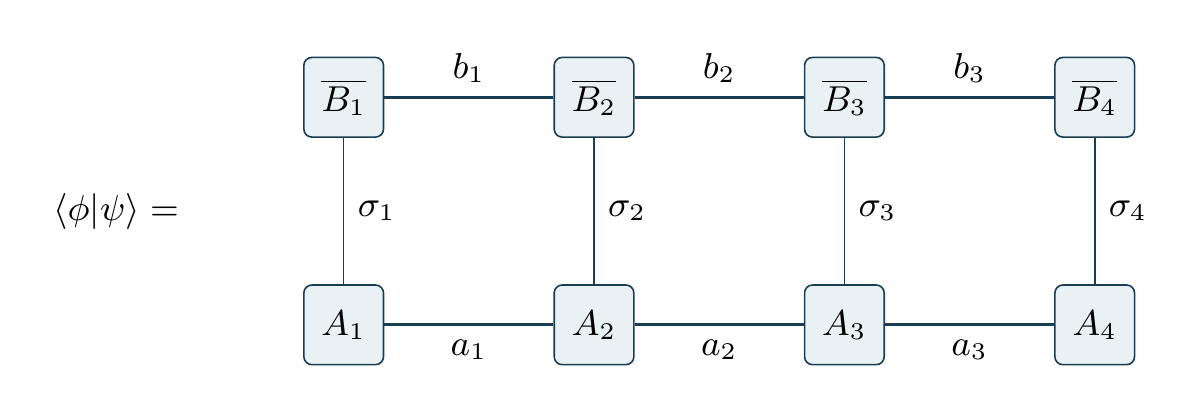

The key question is, what order should the tensor contractions be performed? We could begin by contracting all of the virtual legs of the two tensors, then contract all of the physical legs. Unfortunately, this is incredibly inefficient, it leads to an exponential scaling in the system size because we have lost all of the MPS structure in the system. 

Instead, we will take inspiration from the SVD method used to construct an MPS.  We will sweep through the system from left-to-right (or right-to-left) in an iterative process. Start with a $1\times1$ matrix $L_0=(1)$ and absorb one site at
a time:

$$L_i=\sum_s (A_i^s)^\dagger L_{i-1}A_i^s.$$

The two open legs of $L_i$ are the uncontracted virtual indices of the bra and ket. At the
final boundary $L_N$ is again a $1\times1$ matrix: its entry is $\mathcal N$. The norm itself
is $\|\psi\|=\sqrt{\mathcal N}$.

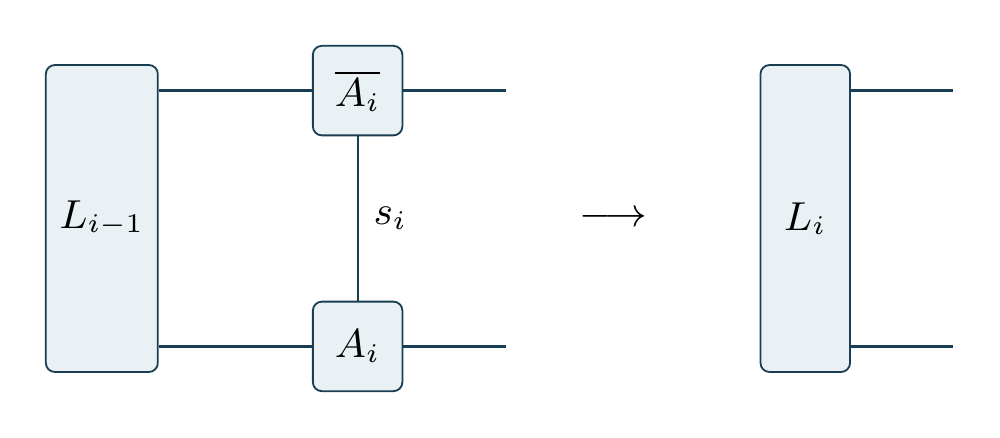

*One step of the norm sweep. The bar denotes complex conjugation; the shared physical leg is summed.*

As before, each site tensor is stored with axes `(physical, left virtual, right virtual)`.
The update below first contracts the ket tensor with `left`, then the conjugate bra tensor
with that intermediate. Each `einsum` follows one contraction step and keeps the
intermediate small. `mps_overlap(mps, mps)` gives the squared norm.

For local dimension $d$ and bond dimensions at most $\chi$, an intermediate $L_i$ has at
most $\chi^2$ entries. Each site costs $O(d\chi^3)$ operations, so the whole sweep costs
$O(Nd\chi^3)$, linear in the number of sites at fixed bond dimension.

In [23]:
def mps_overlap(bra, ket):
    left = np.ones((1, 1))
    for B, A in zip(bra, ket):
        partial = np.einsum("ab,sbc->sac", left, A)
        left = np.einsum("sab,sac->bc", B.conj(), partial)
    return left.item()


def mps_norm_squared(mps):
    return np.real_if_close(mps_overlap(mps, mps)).item()


print("GHZ norm:", np.sqrt(mps_norm_squared(ghz)))

GHZ norm: 0.9999999999999999


### Timing the norm: MPS and a full state vector

Compare $N=14,18,20$. The efficient sweep works directly with the MPS. A full state-vector
calculation, as used in exact diagonalization (ED), stores all $2^N$ coefficients. We time
both its norm **once the vector is available** and **forming that vector from the MPS
before calculating its norm**. 

In [24]:
def dense_norm(state):
    vector = state.reshape(-1)
    return np.sqrt(np.einsum("i,i->", vector.conj(), vector).real)


norm_sizes = [14, 18, 20]
print(f"{'N':>3} {'MPS (us)':>12} {'vector (us)':>14} {'form + norm (us)':>20}")
for n in norm_sizes:
    tensors = ghz_mps(n)
    state = mps_to_tensor(tensors)
    mps_s = median_seconds(lambda: np.sqrt(mps_norm_squared(tensors)))
    vector_s = median_seconds(lambda: dense_norm(state))
    full_s = median_seconds(lambda: dense_norm(mps_to_tensor(tensors)))
    print(f"{n:>3} {1e6*mps_s:>12.2f} {1e6*vector_s:>14.2f} {1e6*full_s:>20.2f}")

  N     MPS (us)    vector (us)     form + norm (us)
 14        63.49          12.53               703.44


 18        33.92         106.12             14707.92


 20        39.68         391.64             46312.29


## 7. Matrix-product operators

An MPS decomposes the coefficients of a wavefunction into a chain of smaller tensors.
We can do the same for an operator,

$$\hat O=\sum_{\boldsymbol s,\boldsymbol t}
O_{s_1\cdots s_N,t_1\cdots t_N}|s_1\cdots s_N\rangle\langle t_1\cdots t_N|.$$

by writing it as a **matrix-product operator (MPO)**:

$$O_{\boldsymbol s,\boldsymbol t}=W_1^{s_1t_1}W_2^{s_2t_2}\cdots W_N^{s_Nt_N}.$$

For fixed physical output and input indices $(s_i,t_i)$, $W_i^{s_it_i}$ is a matrix on the
virtual MPO bonds. As with an open MPS, the boundary virtual dimensions are one. Each bulk
tensor has two physical legs and two virtual legs. We store its axes as
**(physical output, physical input, left virtual, right virtual)**.

Any finite operator can be written as an MPO: a representation can be found by grouping the physical legs and applying successive SVDs, just as in the wavefunction case. The important question is which operators admit finite bond-dimension MPO representations. We will consider three examples below:

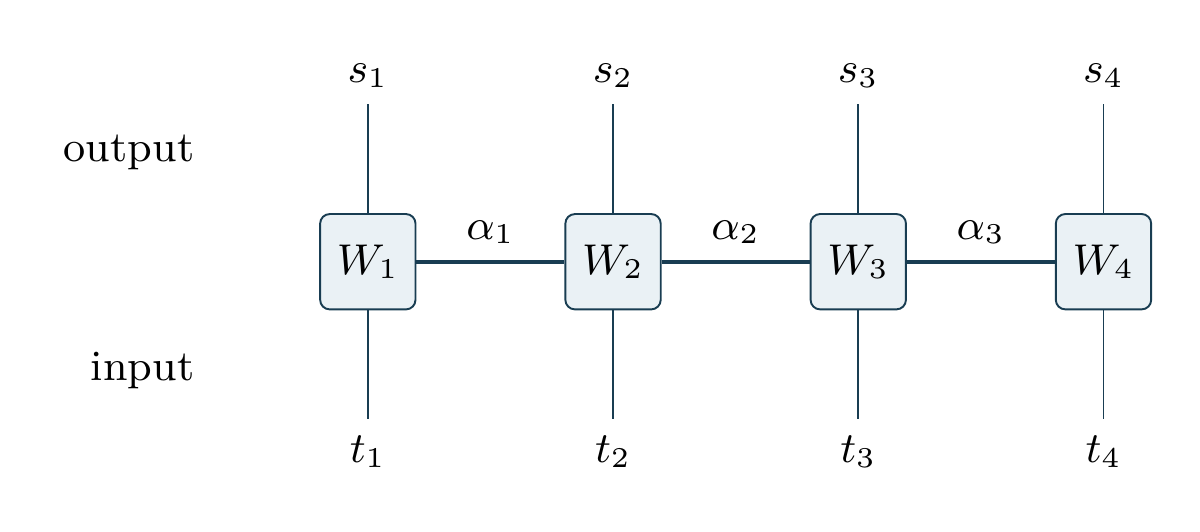

*An MPO is like an MPS but it has two physical legs per site, an input and an output.*

### A simple example: a sum of local operators

It is convenient to write $W_i$ as a matrix whose entries are local operators. A particularly simple but illustrative example of an MPO is writing
$\hat M_z=\sum_i Z_i$, where $Z=\operatorname{diag}(1,-1)$, as

$$W_i=\begin{pmatrix}I&Z\\0&I\end{pmatrix},\qquad
v_L^T=(1,0),\qquad v_R=(0,1)^T.$$

To see how this works, lets contract together two neighbouring $W$ tensors:

$$(W_iW_{i+1})_{ab}=\sum_c (W_i)_{ac}\otimes(W_{i+1})_{cb}.$$

For the sum-of-$Z$ MPO this gives

$$W_iW_{i+1}=\begin{pmatrix}
I\otimes I & I\otimes Z+Z\otimes I\\
0&I\otimes I
\end{pmatrix}.$$

We can see that the correct operator is being deposited in the upper-right, and this is exactly what the boundary vectors select:

$$v_L^T W_1W_2v_R=I\otimes Z+Z\otimes I=Z_1+Z_2.$$

If we continued contracting $W$ tensors we will deposit more and more $Z$ matrices in the upper-right. 

We can interpret this as a **finite-state machine**. The virtual bond labels are its states,
and an arrow from state $a$ to state $b$ determines the operator $W_{ab}$. Each arrow represents
one physical site. For the $M_z$ MPO, we select $I$ until we transition by choosing a $Z$ at one site which transitions us to final state where we choose $I$ again.   

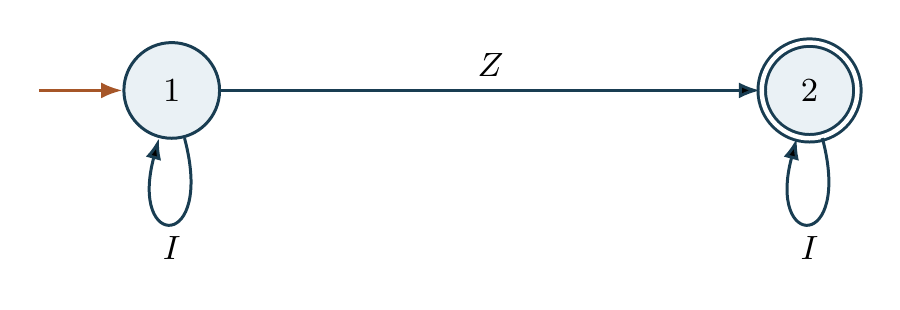

*A finite-state machine representation of the MPO. The single $Z$ transition can occur at any site, generating $\sum_i Z_i$.*


In [25]:
def sum_mpo(operator, n_sites):
    d = operator.shape[0]
    W = np.zeros((d, d, 2, 2), dtype=operator.dtype)
    W[:, :, 0, 0] = W[:, :, 1, 1] = np.eye(d)
    W[:, :, 0, 1] = operator
    mpo = [W.copy() for _ in range(n_sites)]
    mpo[0] = mpo[0][:, :, :1, :]
    mpo[-1] = mpo[-1][:, :, :, -1:]
    return mpo


pauli_z = np.diag([1., -1.])
magnetization_mpo = sum_mpo(pauli_z, len(ghz))
print("MPO tensor shapes:", [W.shape for W in magnetization_mpo])

MPO tensor shapes: [(2, 2, 1, 2), (2, 2, 2, 2), (2, 2, 2, 2), (2, 2, 2, 2), (2, 2, 2, 2), (2, 2, 2, 1)]


For a two-site chain, `sum_mpo` has already absorbed the boundary vectors.
Contract the shared virtual index `u`, then group the two output indices `(s, v)` and the
two input indices `(t, w)` to form the full operator matrix. The remaining boundary
indices `a` and `b` both have dimension one.
In the basis $|00\rangle,|01\rangle,|10\rangle,|11\rangle$, the result is
$\operatorname{diag}(2,0,0,-2)$, as expected for $Z_1+Z_2$.

In [26]:
W1, W2 = sum_mpo(pauli_z, 2)
two_site_z = np.einsum("stau,vwub->svtwab", W1, W2).reshape(4, 4)
print(two_site_z)

[[ 2.  0.  0.  0.]
 [ 0.  0.  0.  0.]
 [ 0.  0.  0.  0.]
 [ 0.  0.  0. -2.]]


### Transverse-field Ising model

A nontrivial local Hamiltonian contains both single-site terms and interactions between
neighbouring sites. The transverse-field Ising Hamiltonian is a good example:

$$H_{\mathrm{TFIM}}=J\sum_{i=1}^{N-1}Z_iZ_{i+1}+h\sum_{i=1}^N X_i,\qquad
X=\begin{pmatrix}0&1\\1&0\end{pmatrix}.$$

It has a bond-dimension-three MPO,

$$W_i=\begin{pmatrix}
I&Z&hX\\0&0&JZ\\0&0&I
\end{pmatrix},\qquad v_L^T=(1,0,0),\quad v_R=(0,0,1)^T.$$

We get a contribution that is $hX$ at one site and $I$ elsewhere, or $Z$ followed immediately by $JZ$ at the
next site and $I$ elsewhere. For two sites this gives
$h(X\otimes I+I\otimes X)+JZ\otimes Z$. 

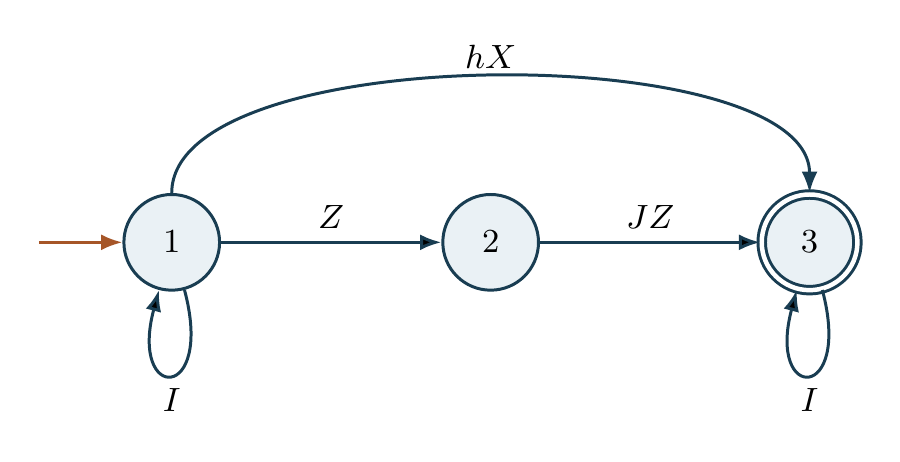



In [27]:
def ising_mpo(n_sites, J=-1., h=-0.7):
    W = np.zeros((2, 2, 3, 3))
    W[:, :, 0, 0] = W[:, :, 2, 2] = np.eye(2)
    W[:, :, 0, 1] = np.diag([1., -1.])
    W[:, :, 0, 2] = h * np.array([[0., 1.], [1., 0.]])
    W[:, :, 1, 2] = J * np.diag([1., -1.])
    mpo = [W.copy() for _ in range(n_sites)]
    mpo[0] = mpo[0][:, :, :1, :]
    mpo[-1] = mpo[-1][:, :, :, -1:]
    return mpo

### Exponentially decaying interactions

MPOs can also represent certain kinds of longer range interactions between distant sites. Consider a Hamiltonian with exponentially decaying interactions:

$$H_{\exp}=\sum_{1\leq i<j\leq N}\lambda^{j-i}X_iX_j,\qquad 0<\lambda<1.$$

This can be produced by putting $\lambda I$ elements along the diagonal:

$$W_i=\begin{pmatrix}
I&X&0\\0&\lambda I&\lambda X\\0&0&I
\end{pmatrix},\qquad v_L^T=(1,0,0),\quad v_R=(0,0,1)^T.$$

A path starts an interaction at $i$, remains in the middle state for $j-i-1$ sites, and
finishes at $j$. Its coefficient is $1\times\lambda^{j-i-1}\times\lambda=\lambda^{j-i}$.
For three sites this gives
$\lambda(X_1X_2+X_2X_3)+\lambda^2X_1X_3$.
The nearest-neighbour coefficient is $\lambda$ in this convention. The couplings decay
exponentially with distance, while the MPO bond dimension remains three for any chain length.

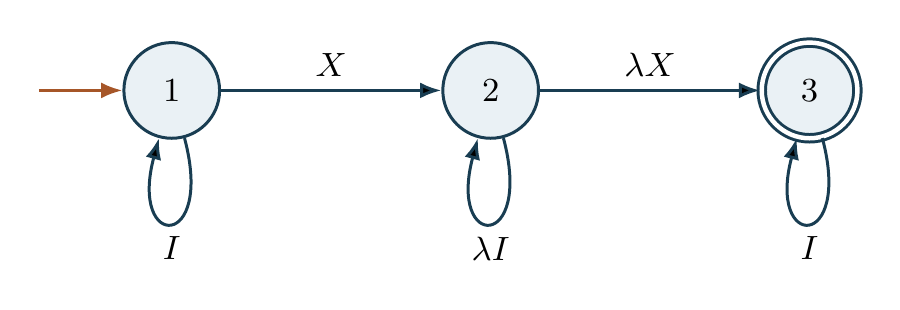

In [28]:
def exponential_mpo(n_sites, decay=0.5):
    X = np.array([[0., 1.], [1., 0.]])
    W = np.zeros((2, 2, 3, 3))
    W[:, :, 0, 0] = W[:, :, 2, 2] = np.eye(2)
    W[:, :, 0, 1] = X
    W[:, :, 1, 1] = decay * np.eye(2)
    W[:, :, 1, 2] = decay * X
    mpo = [W.copy() for _ in range(n_sites)]
    mpo[0] = mpo[0][:, :, :1, :]
    mpo[-1] = mpo[-1][:, :, :, -1:]
    return mpo

### Expectation values of MPOs

Suppose we want to calculate the expectation value of an MPO: $\langle\psi|\hat O|\psi\rangle$. This is a three-layer MPS--MPO--MPS contraction that looks similar to the norm calculation.

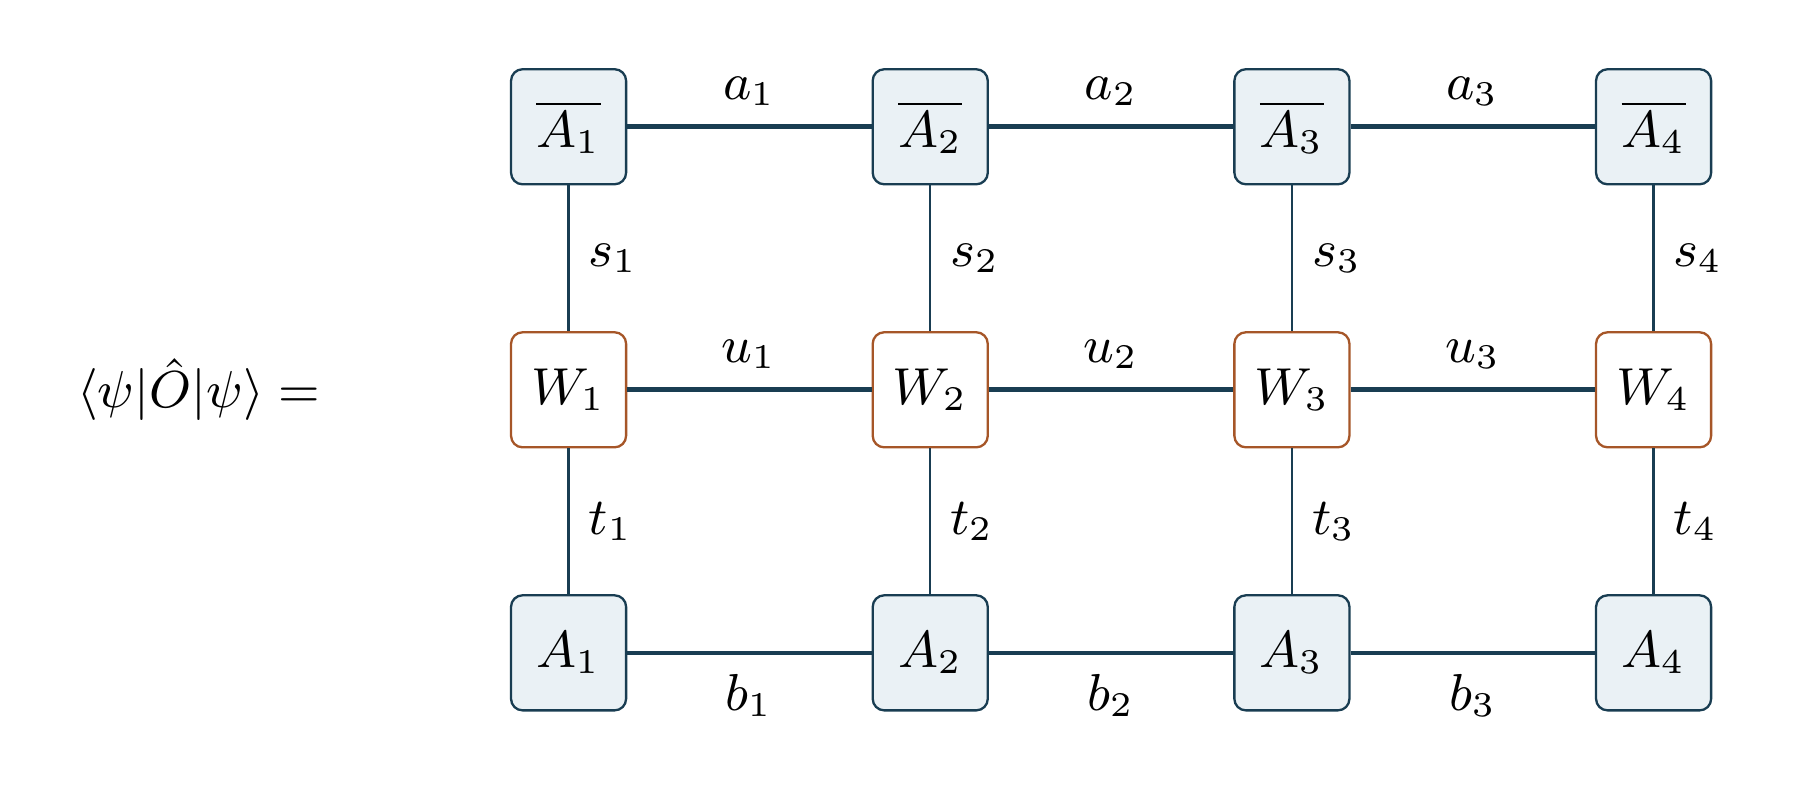

We can contract it using the same sweep introduced for the norm. We denote MPO environments
by $F_L$ and $F_R$, while reserving $L$ and $R$ for the MPS norm environments. The left environment
$F_{L,i}$ contracts sites $1,\ldots,i$ and has three indices: a bra bond $a$, an MPO bond
$u$, and a ket bond $b$. Starting with $F_{L,0}=(1)$, absorb one site at a time:

$$(F_{L,i})_{dvc}=\sum_{a,u,b,s,t}(F_{L,i-1})_{aub}
\overline{(A_i^s)_{ad}}(W_i^{st})_{uv}(A_i^t)_{bc}.$$

Similarly, $F_{R,i}$ contracts sites $i,\ldots,N$ from the right boundary, starting with
$F_{R,N+1}=(1)$.

At the final boundary all three dimensions are one, giving the expectation value (for a normalised MPS). Once again the cost is linear in the number of sites.

The three `einsum` calls below contract the ket first, then the MPO, then the bra. This
keeps only a small intermediate at every step. For the identity MPO, the operator bond has
dimension one and we recover the norm sweep.

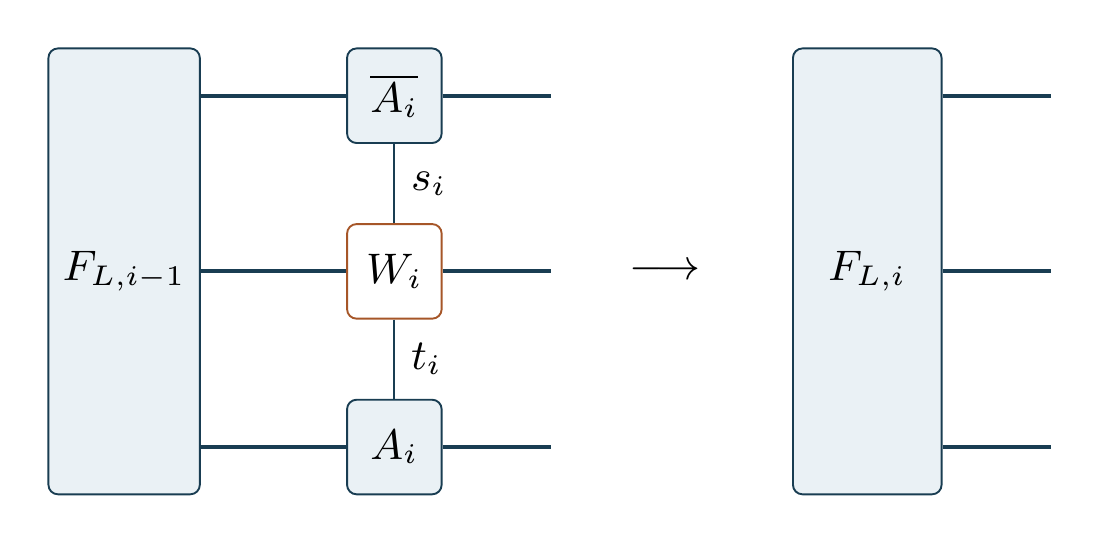

In [29]:
def left_environment(F_L, tensor, W):
    partial = np.einsum("aub,tbc->autc", F_L, tensor)
    partial = np.einsum("autc,stuv->asvc", partial, W)
    return np.einsum("sad,asvc->dvc", tensor.conj(), partial)


def mpo_expectation(mps, mpo):
    F_L = np.ones((1, 1, 1))
    for tensor, W in zip(mps, mpo):
        F_L = left_environment(F_L, tensor, W)
    return np.real_if_close(F_L.item() / mps_norm_squared(mps)).item()

For $|00\cdots0\rangle$, every $Z_i$ gives $+1$, so $\langle\hat M_z\rangle=N$.
In the GHZ state the two branches have opposite total magnetizations and equal weight,
so the expectation value is zero. Neither calculation needs the full wavefunction.

In [30]:
polarized_mps = [np.array([1., 0.]).reshape(2, 1, 1) for _ in ghz]
print("Polarized state <sum Z>:", mpo_expectation(polarized_mps, magnetization_mpo))
print("GHZ state <sum Z>:", mpo_expectation(ghz, magnetization_mpo))

Polarized state <sum Z>: 6.0
GHZ state <sum Z>: 0.0


The same sweep contracts both Hamiltonians above. For $|00\cdots0\rangle$, each $Z_iZ_{i+1}$
has expectation one and each $X_i$ has expectation zero, so
$\langle H_{\mathrm{TFIM}}\rangle=J(N-1)$.
For $|+\rangle^{\otimes N}$, where $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$, these roles
reverse and $\langle H_{\mathrm{TFIM}}\rangle=hN$.

In the same $X$-polarized state every $X_iX_j$ has expectation one. There are $N-r$ pairs
at separation $r$, giving

$$\langle H_{\exp}\rangle=\sum_{r=1}^{N-1}(N-r)\lambda^r.$$

For six sites with $\lambda=1/2$, this is $4.03125$. These calculations use exactly the
same expectation-value function as the sum-of-$Z$ example.

In [31]:
plus_mps = [np.array([1., 1.]).reshape(2, 1, 1) / np.sqrt(2) for _ in ghz]
tfim_mpo = ising_mpo(len(ghz))
long_range_mpo = exponential_mpo(len(ghz), decay=0.5)
print("Z-polarized state <H_TFIM>:", mpo_expectation(polarized_mps, tfim_mpo))
print("X-polarized state <H_TFIM>:", mpo_expectation(plus_mps, tfim_mpo))
print("X-polarized state <H_exp>:", mpo_expectation(plus_mps, long_range_mpo))

Z-polarized state <H_TFIM>: -5.0
X-polarized state <H_TFIM>: -4.2
X-polarized state <H_exp>: 4.03125


## 8. Gauge freedom and canonical forms

The MPS tensors are not uniquely determined by the physical state. We can always insert
$XX^{-1}=I$ on an internal bond, with $X$ invertible, and absorb the factors into adjacent
tensors:

$$A_i^s\longmapsto A_i^sX,\qquad
A_{i+1}^s\longmapsto X^{-1}A_{i+1}^s.$$

This leaves the wavefunction unchanged while transforming the underlying tensors. We can
use this **gauge freedom** to choose a convenient representation. In particular, we want
the effective states of the blocks to the left and right to be orthonormal. This is called
a **canonical form**.

In a left gauge, the tensors before the final site are left-canonical and the final tensor
carries the remaining norm. The right gauge is the opposite. A mixed gauge places
a centre tensor $A_C$ between left-canonical tensors $A_L$ and right-canonical tensors $A_R$.

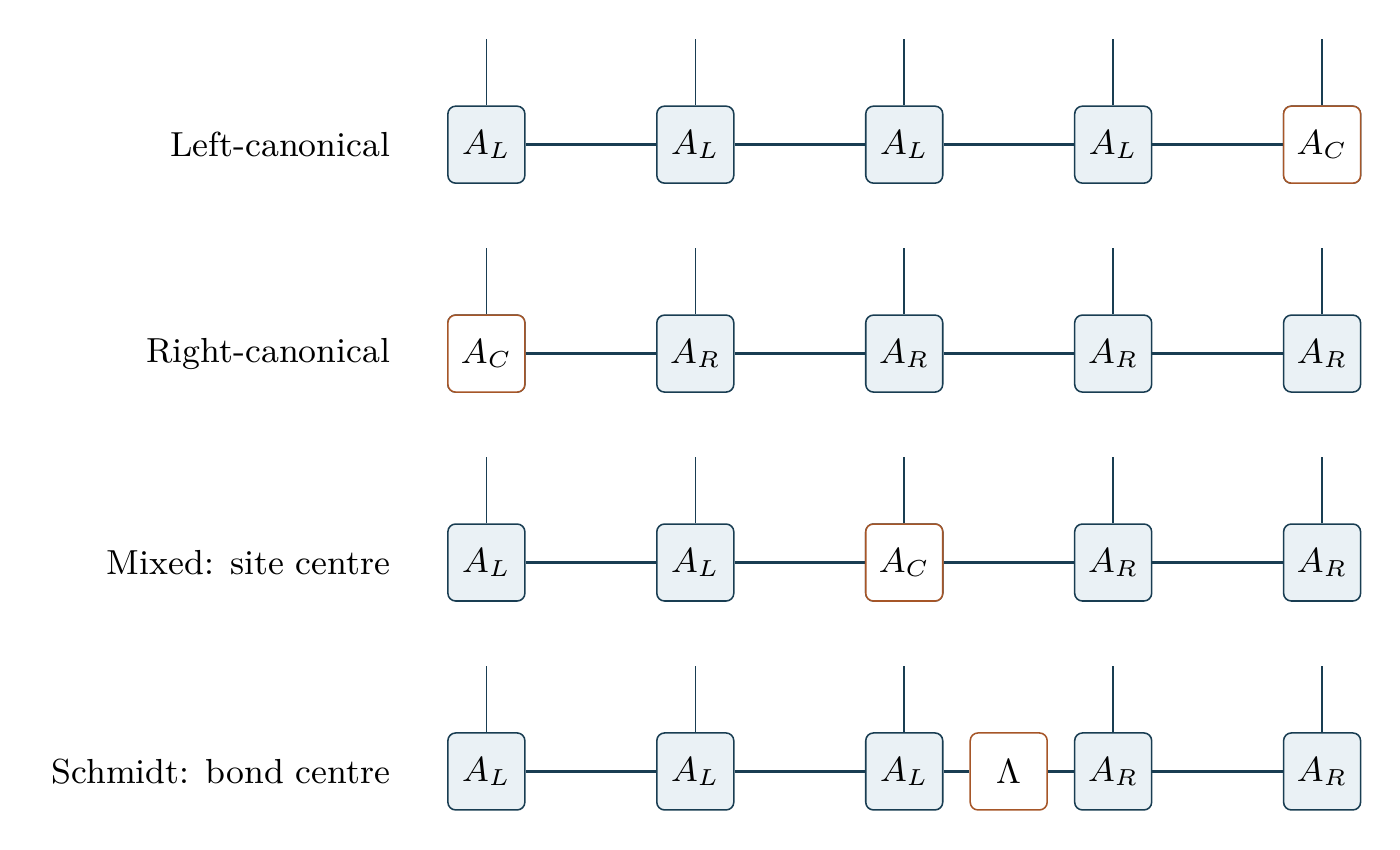


### The left and right gauge conditions

The successive SVDs used to construct an MPS already provide what we need to find the canonical form.
Because each $U$ has orthonormal columns, a left-to-right SVD gives tensors satisfying

$$\sum_s(A_L^s)^\dagger A_L^s=I.$$

Starting from the left boundary, this identity makes the left-block states orthonormal.
A right-to-left SVD instead keeps the orthonormal rows of $V^\dagger$, giving

$$\sum_s A_R^s(A_R^s)^\dagger=I.$$

These identities explain the names: a left-canonical tensor cancels with its conjugate
when contracted from the left; a right-canonical tensor cancels when contracted from the
right. The uncontracted legs form the corresponding identity on the remaining virtual bond.

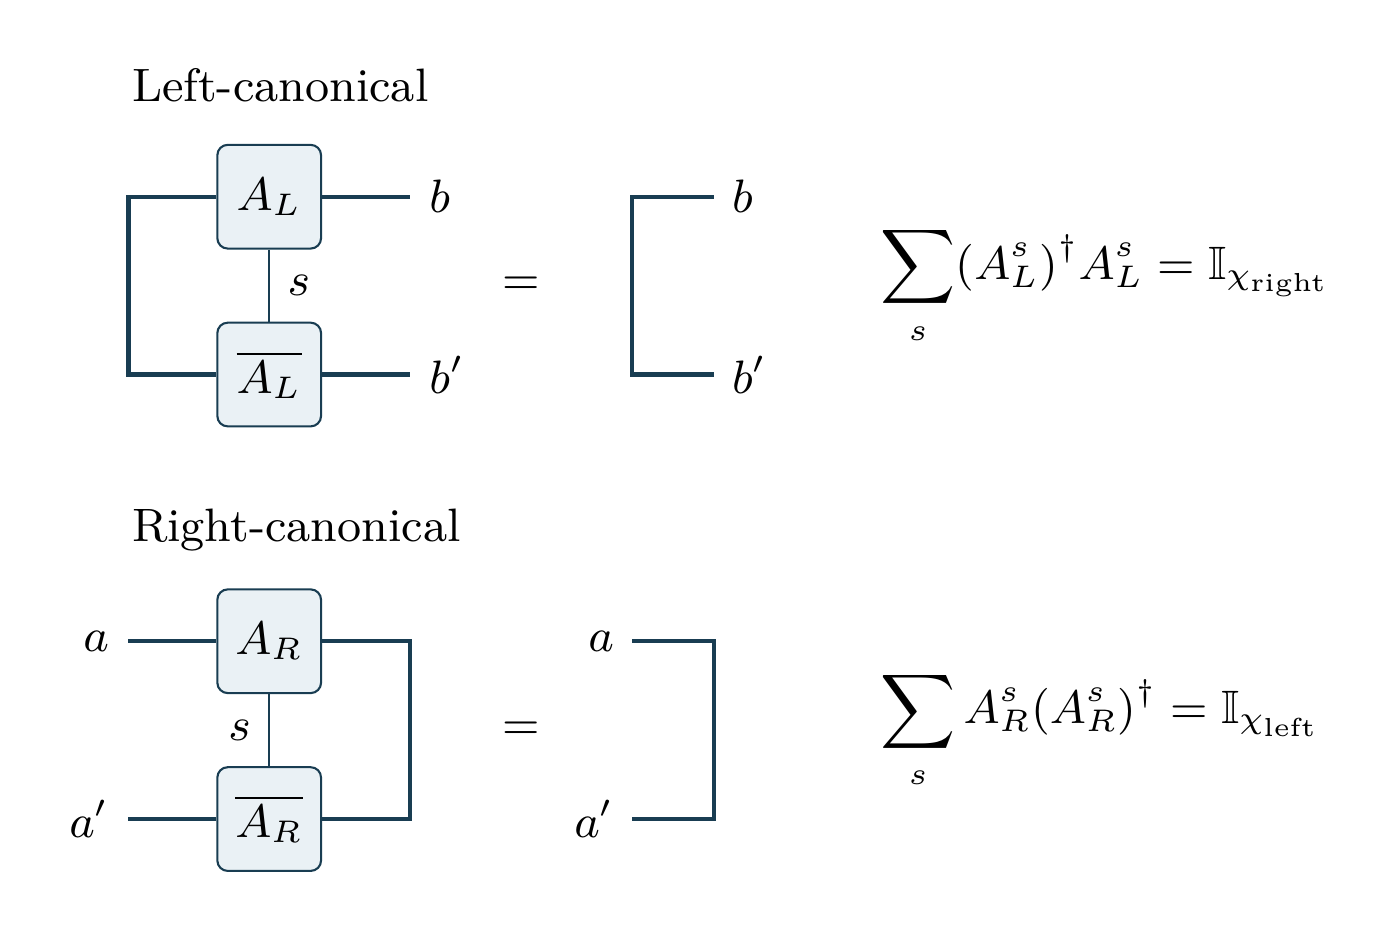


### Move the centre to the right

Reshape the centre tensor as a matrix with row index $(a,s)$ and column index $b$.
Take its SVD, retain $U$ as the new $A_L$, and absorb $SV^\dagger$ into the next site.
This preserves the state and moves the centre one site to the right. We keep all singular
values here: changing gauge does not compress or normalize the state.

The functions below update the supplied tensor list in place.

In [32]:
def shift_right(mps, site):
    d, left, right = mps[site].shape
    matrix = mps[site].transpose(1, 0, 2).reshape(left * d, right)
    U, s, Vh = np.linalg.svd(matrix, full_matrices=False)
    mps[site] = U.reshape(left, d, len(s)).transpose(1, 0, 2)
    remainder = np.einsum("a,ab->ab", s, Vh)
    mps[site + 1] = np.einsum("ab,sbc->sac", remainder, mps[site + 1])

### Move the centre to the left

Now group the physical index with the right virtual index. Keep $V^\dagger$ as the new
$A_R$ and absorb $US$ into the previous site.

In [33]:
def shift_left(mps, site):
    d, left, right = mps[site].shape
    matrix = mps[site].transpose(1, 0, 2).reshape(left, d * right)
    U, s, Vh = np.linalg.svd(matrix, full_matrices=False)
    mps[site] = Vh.reshape(len(s), d, right).transpose(1, 0, 2)
    remainder = np.einsum("ab,b->ab", U, s)
    mps[site - 1] = np.einsum("sab,bc->sac", mps[site - 1], remainder)

### Mixed gauge and the norm of the centre

Sweeping from both boundaries to a chosen site gives the centre gauge. `center=0` gives a
right gauge, while `center=len(mps)-1` gives a left gauge. An interior site gives mixed
canonical form:

$$|\psi\rangle=\sum_{a,s,b}(A_C^s)_{ab}|a_L\rangle|s\rangle|b_R\rangle.$$

Both block bases are orthonormal, so all the surrounding norm tensors contract to
identities. Consequently,

$$\langle\psi|\psi\rangle=\sum_{a,s,b}|(A_C^s)_{ab}|^2.$$

In [34]:
def mixed_canonical(mps, center):
    tensors = [tensor.copy() for tensor in mps]
    for site in range(center):
        shift_right(tensors, site)
    for site in range(len(tensors) - 1, center, -1):
        shift_left(tensors, site)
    return tensors


center = 2  # Python counts sites from zero.
mixed_mps = mixed_canonical(ghz_mps(6), center)
A_L, A_C, A_R = mixed_mps[center - 1:center + 2]
print("Left gauge condition:", np.einsum("sab,sac->bc", A_L.conj(), A_L), sep="\n")
print("Right gauge condition:", np.einsum("sab,scb->ac", A_R, A_R.conj()), sep="\n")
print("Norm from the centre:", np.linalg.norm(A_C))

Left gauge condition:
[[1. 0.]
 [0. 1.]]
Right gauge condition:
[[1. 0.]
 [0. 1.]]
Norm from the centre: 0.9999999999999999


### Connection to the Schmidt decomposition

In mixed gauge, reshape $A_C$ into a matrix by grouping the left virtual and physical
indices. Its SVD gives the **Schmidt decomposition** across the bond to the right of the
centre:

$$|\psi\rangle=\sum_\alpha\lambda_\alpha
|\alpha_L\rangle|\alpha_R\rangle,\qquad
\langle\alpha_L|\beta_L\rangle=\langle\alpha_R|\beta_R\rangle=\delta_{\alpha\beta}.$$

The singular values $\lambda_\alpha$ are the Schmidt coefficients. They appear as the
diagonal bond tensor $\Lambda$ in the figure above. For a normalized state,
$\sum_\alpha\lambda_\alpha^2=1$; for GHZ the two nonzero coefficients are both $1/\sqrt2$.
This also explains the earlier SVD truncation: in an orthonormal block basis, keeping the
largest Schmidt coefficients gives the best approximation across that cut.

In [35]:
d, left, right = A_C.shape
center_matrix = A_C.transpose(1, 0, 2).reshape(left * d, right)
schmidt_values = np.linalg.svd(center_matrix, compute_uv=False)
print("GHZ Schmidt coefficients:", schmidt_values)

GHZ Schmidt coefficients: [0.7071 0.7071]


## 9. DMRG: finding a ground state

For a Hermitian Hamiltonian, the ground state minimizes

$$E[\psi]=\frac{\langle\psi|H|\psi\rangle}{\langle\psi|\psi\rangle}.$$

**Density-matrix renormalization group (DMRG)** uses the variational principle to optimize
an MPS. The dependence on all tensors together is **nonlinear**. With every tensor except $A_C$ fixed, however, the state depends **linearly** on the central tensor. All tensors outside the local tensor can therefore be contracted into the left and right Hamiltonian environments
$F_L$ and $F_R$ introduced for MPO expectation values.

We use the transverse-field Ising Hamiltonian from Section 7 with $J=-1$ and $h=-0.95$,
close to the infinite-chain critical point at $|h/J|=1$.


### The central DMRG algorithm

DMRG works by putting the MPS into mixed canonical form at site $n$ and flattening $A_C$ into a vector $a_c=\operatorname{vec}(A_C)$. The left and right block bases are orthonormal, so
$\langle\psi(a_c)|\psi(a_c)\rangle=a_c^\dagger a_c$.

The effective Hamiltonian $H_{\mathrm{eff}}$ contracts $F_{L,n-1}$, $W_n$ and $F_{R,n+1}$.
With all surrounding tensors fixed, the local energy is

$$E(a_c)=\frac{a_c^\dagger H_{\mathrm{eff}}a_c}{a_c^\dagger a_c}.$$

If we simply solve this eigenvalue problem, we can find a way to minimize the energy of the MPS:

$$H_{\mathrm{eff}}a'_c=E_{\mathrm{local}}a'_c.$$

We can then reshape this updated vector $a'_c$ into the centre tensor $A'_C$, insert it into the MPS, and move to another site of the system.

Without the mixed gauge, this would be a generalised eigenvalue problem involving the $L$ and $R$ norm tensors. In general this would be significantly less stable and reliable, for this reason the mixed MPS gauge is central to the performance of DMRG.
 
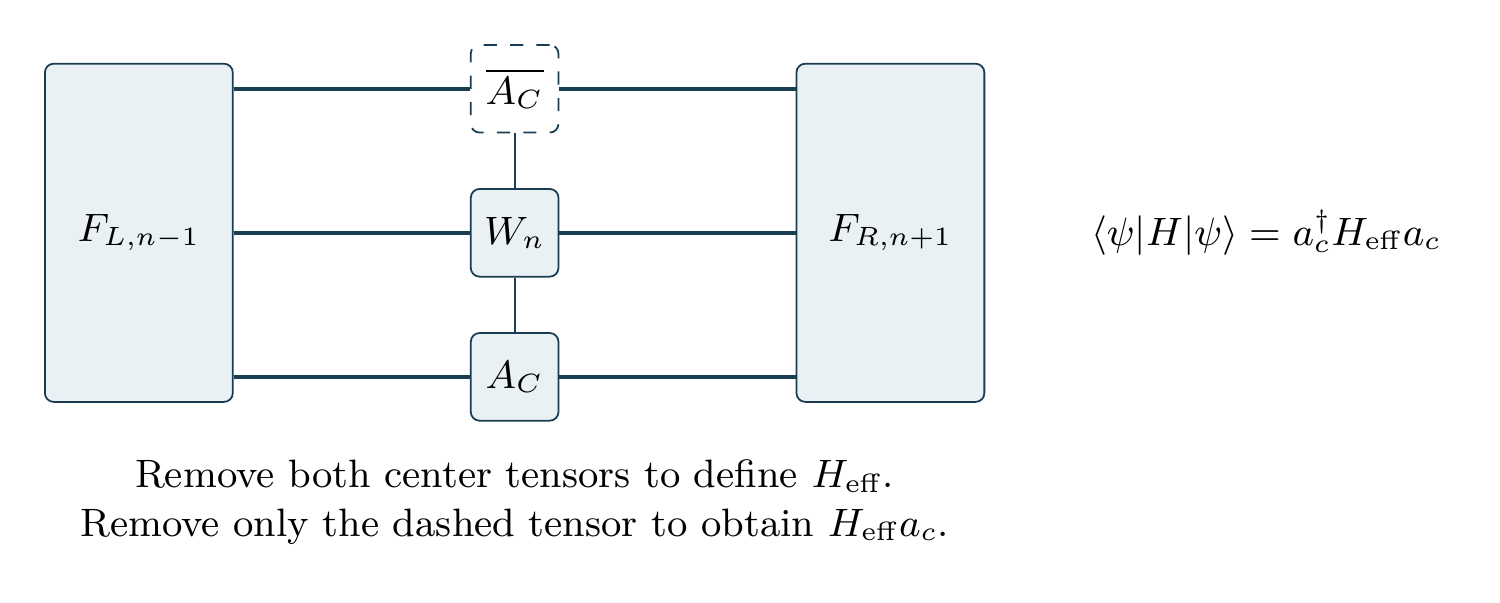


`np.linalg.eigh` can be used to solve the eigenproblem. For this small example we form
$H_{\mathrm{eff}}$ explicitly. Its dimension is $d\chi_{n-1}\chi_n$, rather than the full
$2^N$ Hilbert-space dimension, a huge improvement!
But we can do even better. For large bonds, practical DMRG uses an iterative eigensolver which simply calculates the action of $H_{\mathrm{eff}}$ on $a_c$. By doing this a small number of times (typically 10-20), the eigenvalue problem can be effictively solved without even storing $H_{\mathrm{eff}}$ in memory! 

In [36]:
def right_environment(F_R, tensor, W):
    partial = np.einsum("tbc,dvc->tbdv", tensor, F_R)
    partial = np.einsum("stuv,tbdv->subd", W, partial)
    return np.einsum("sad,subd->aub", tensor.conj(), partial)


def local_ground_state(F_L, W, F_R, shape):
    H_eff = np.einsum("aub,stuv,dvc->sadtbc", F_L, W, F_R, optimize=True)
    H_eff = H_eff.reshape(np.prod(shape), np.prod(shape))
    values, vectors = np.linalg.eigh(H_eff)
    return vectors[:, 0].reshape(shape)

### One DMRG sweep

Start with a normalized random MPS whose centre is at the left boundary. At each site:

1. Find the lowest-energy centre tensor with the surrounding tensors fixed.
2. Move the centre by SVD, leaving a canonical tensor behind.
3. Update $F_L$ or $F_R$ on the side just completed.


In [37]:
def dmrg(mps, mpo, sweeps=4):
    n = len(mps)
    energies = [mpo_expectation(mps, mpo)]
    for sweep in range(sweeps):
        F_R = [None] * (n + 1)
        F_R[n] = np.ones((1, 1, 1))
        for site in range(n - 1, 0, -1):
            F_R[site] = right_environment(F_R[site + 1], mps[site], mpo[site])

        F_L = [np.ones((1, 1, 1))]
        for site in range(n):
            mps[site] = local_ground_state(F_L[site], mpo[site], F_R[site + 1], mps[site].shape)
            if site < n - 1:
                shift_right(mps, site)
                F_L.append(left_environment(F_L[site], mps[site], mpo[site]))

        F_R = np.ones((1, 1, 1))
        for site in range(n - 1, -1, -1):
            mps[site] = local_ground_state(F_L[site], mpo[site], F_R, mps[site].shape)
            if site > 0:
                shift_left(mps, site)
                F_R = right_environment(F_R, mps[site], mpo[site])
        energies.append(mpo_expectation(mps, mpo))
    return np.array(energies)

In [192]:
dmrg_n = 32
bond_dimension = 10
J_in, h_in = -1., -0.5
bonds = [min(bond_dimension, 2**min(i, dmrg_n - i)) for i in range(dmrg_n + 1)]
dmrg_rng = np.random.default_rng(7)
dmrg_mps = [dmrg_rng.normal(size=(2, bonds[i], bonds[i + 1])) for i in range(dmrg_n)]
dmrg_mps = mixed_canonical(dmrg_mps, 0)
dmrg_mps[0] /= np.linalg.norm(dmrg_mps[0])
hamiltonian_mpo = ising_mpo(dmrg_n, J_in, h_in)
energy_history = dmrg(dmrg_mps, hamiltonian_mpo)
for sweep, energy in enumerate(energy_history):
    print(f"Sweep {sweep}: energy = {energy:.10f}")

Sweep 0: energy = -0.4675650248
Sweep 1: energy = -33.1627500715
Sweep 2: energy = -33.1627500715
Sweep 3: energy = -33.1627500715
Sweep 4: energy = -33.1627500715


## 10. Time evolution with TEBD

We have used DMRG to find a ground state. How can we follow a state as it evolves in time?
For a time-independent Hamiltonian, with $\hbar=1$,

$$|\psi(t+\delta t)\rangle=e^{-iH\delta t}|\psi(t)\rangle.$$

The full evolution operator is exponentially large. **Time-evolving block decimation
(TEBD)** instead applies small local gates to an MPS, using SVD to control the bond
dimensions after each two-site update. The ingredients are the canonical gauges and
Schmidt truncation introduced above, together with a short-time approximation to the
propagator.

### Split the evolution into odd/even bond layers

Write a nearest-neighbour Hamiltonian as a sum of two-site operators,

$$H=\sum_{i=0}^{N-2}h_i=H_{\mathrm{even}}+H_{\mathrm{odd}},\qquad
H_{\mathrm{even}}=\sum_{i\ \mathrm{even}}h_i,\qquad
H_{\mathrm{odd}}=\sum_{i\ \mathrm{odd}}h_i.$$

Bond $i$ joins Python sites $i$ and $i+1$. Thus even bonds are $(0,1),(2,3),\ldots$,
and odd bonds are $(1,2),(3,4),\ldots$. Bonds within one layer do not share sites,
so their operators commute. Neighbouring bonds from different layers generally do not.
The symmetric **Suzuki--Trotter decomposition** gives

$$e^{-iH\delta t}=e^{-iH_{\mathrm{even}}\delta t/2}
 e^{-iH_{\mathrm{odd}}\delta t}
 e^{-iH_{\mathrm{even}}\delta t/2}+O(\delta t^3).$$

One timestep therefore applies **even half steps, odd full steps, then even half steps**.
We denote the two-site unitaries by

$$u_i^{\mathrm{even}}(\tau)=e^{-ih_i\tau}\quad(i\ \mathrm{even}),\qquad
u_i^{\mathrm{odd}}(\tau)=e^{-ih_i\tau}\quad(i\ \mathrm{odd}).$$

The outer layers use $u_i^{\mathrm{even}}(\delta t/2)$ and the middle layer uses
$u_i^{\mathrm{odd}}(\delta t)$. The local error is $O(\delta t^3)$;
at fixed total evolution time the accumulated Trotter error is $O(\delta t^2)$.

For the same Ising model as before, the two-site matrices are

$$h_i=JZ\otimes Z+h\left(w_iX\otimes I+w_{i+1}I\otimes X\right),\qquad
w_0=w_{N-1}=1,\quad w_i=\tfrac12\ \text{in the interior}.$$

The field is shared between neighbouring bonds. Each interior spin occurs in two bond
terms and each end spin in one, so $\sum_i h_i$ contains exactly $h\sum_iX_i$ and
$J\sum_iZ_iZ_{i+1}$. This bond construction is for an open chain with at least two sites.

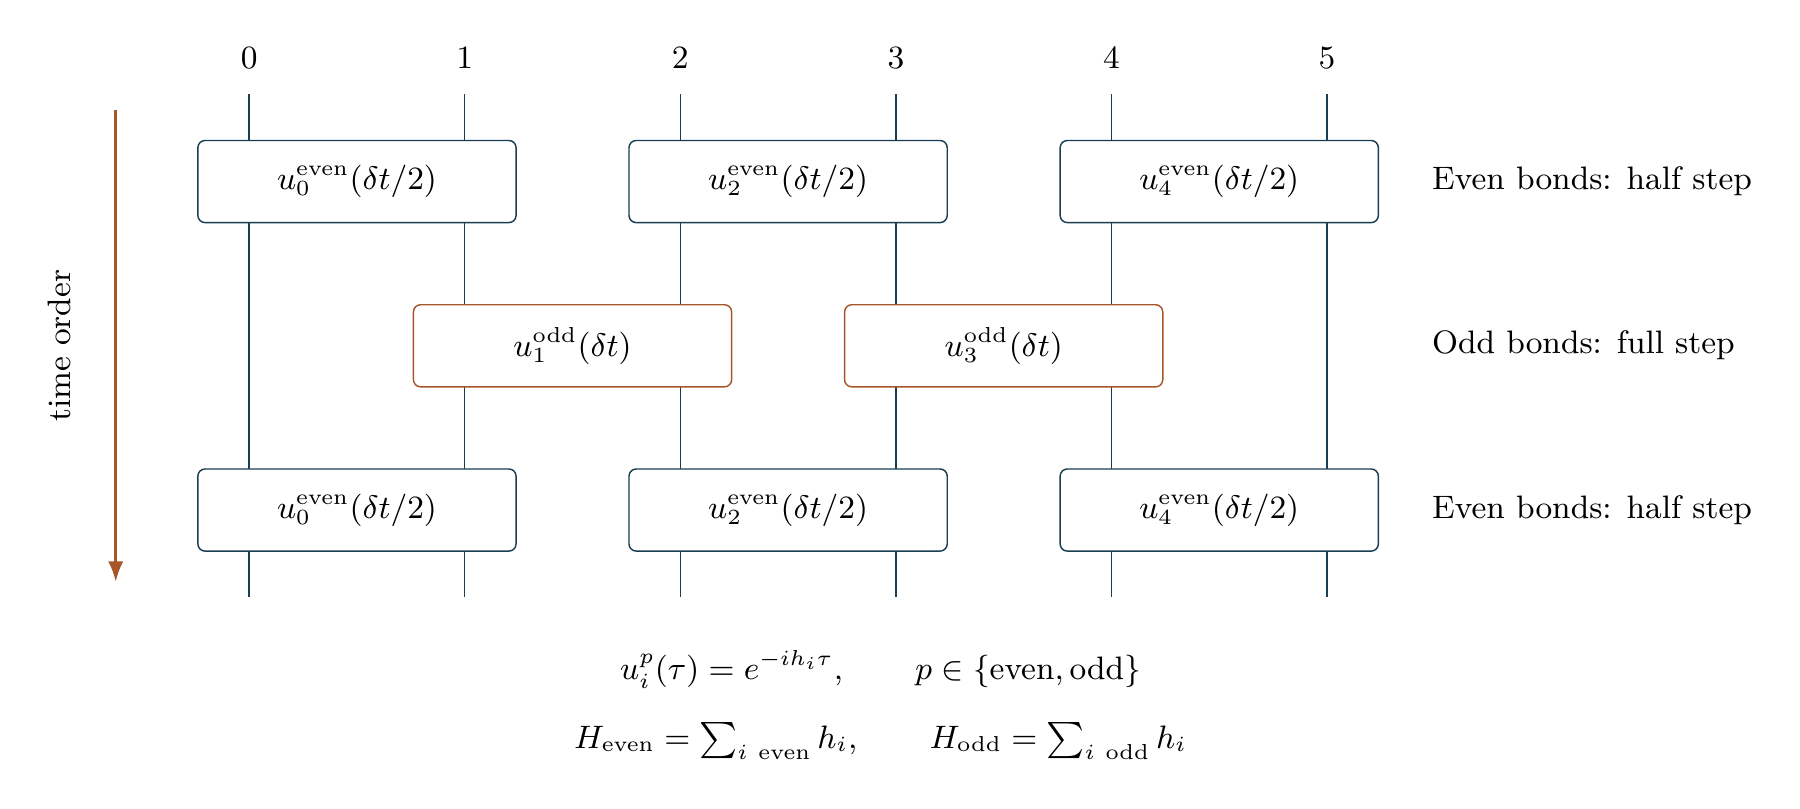

*One second-order TEBD timestep. Bond numbers follow Python's zero-based indexing; gates within each row act on disjoint pairs.*

To calculate a gate, diagonalize its small Hermitian Hamiltonian:
$h_{\mathrm{local}}=V\operatorname{diag}(\epsilon)V^\dagger$. Then
$e^{-ih_{\mathrm{local}}t}=V\operatorname{diag}(e^{-i\epsilon t})V^\dagger$.
The two-site gate is stored with axes **(output 1, output 2, input 1, input 2)**.

In [40]:
def time_gate(local_hamiltonian, time):
    values, vectors = np.linalg.eigh(local_hamiltonian)
    return np.einsum("ak,k,bk->ab", vectors, np.exp(-1j * time * values), vectors.conj())


def ising_unitaries(n_sites, dt, J, h):
    I = np.eye(2)
    X = np.array([[0., 1.], [1., 0.]])
    Z = np.diag([1., -1.])
    ZZ = np.einsum("ab,cd->acbd", Z, Z).reshape(4, 4)
    XI = np.einsum("ab,cd->acbd", X, I).reshape(4, 4)
    IX = np.einsum("ab,cd->acbd", I, X).reshape(4, 4)
    weights = np.full(n_sites, 0.5)
    weights[[0, -1]] = 1.
    unitaries = []
    for site in range(n_sites - 1):
        bond_hamiltonian = J * ZZ + h * (weights[site] * XI + weights[site + 1] * IX)
        bond_time = dt / 2 if site % 2 == 0 else dt
        unitaries.append(time_gate(bond_hamiltonian, bond_time).reshape(2, 2, 2, 2))
    return unitaries

### Apply a two-site gate and split by SVD

Place the orthogonality centre at site $i$ and merge its tensor with the tensor at $i+1$:

$$\Theta^{st}_{ab}=\sum_c(A_C^s)_{ac}(A_R^t)_{cb},\qquad
\widetilde\Theta^{s't'}_{ab}=\sum_{s,t}\bigl(u_i^p(\tau)\bigr)_{s't',st}\Theta^{st}_{ab},\quad p\in\{\mathrm{even},\mathrm{odd}\}.$$

Reshape $\widetilde\Theta$ as a matrix with row index $(a,s')$ and column index $(t',b)$.
Take its SVD, keeping at most $\chi$ singular values. Reshape $U$ into $A_L$ and $SV^\dagger$
into the new $A_C$ at site $i+1$. The centre has moved one site to the right.

The exterior blocks are orthonormal, so the singular values are Schmidt coefficients for
this cut. The relative discarded weight is

$$\epsilon_{\mathrm{disc}}=\frac{\sum_{\alpha>\chi}s_\alpha^2}
{\sum_\alpha s_\alpha^2}.$$

The update returns this number and leaves the retained state unnormalized. Unlike the
one-site DMRG sweep, this two-site update can increase a bond dimension, up to the chosen cap.

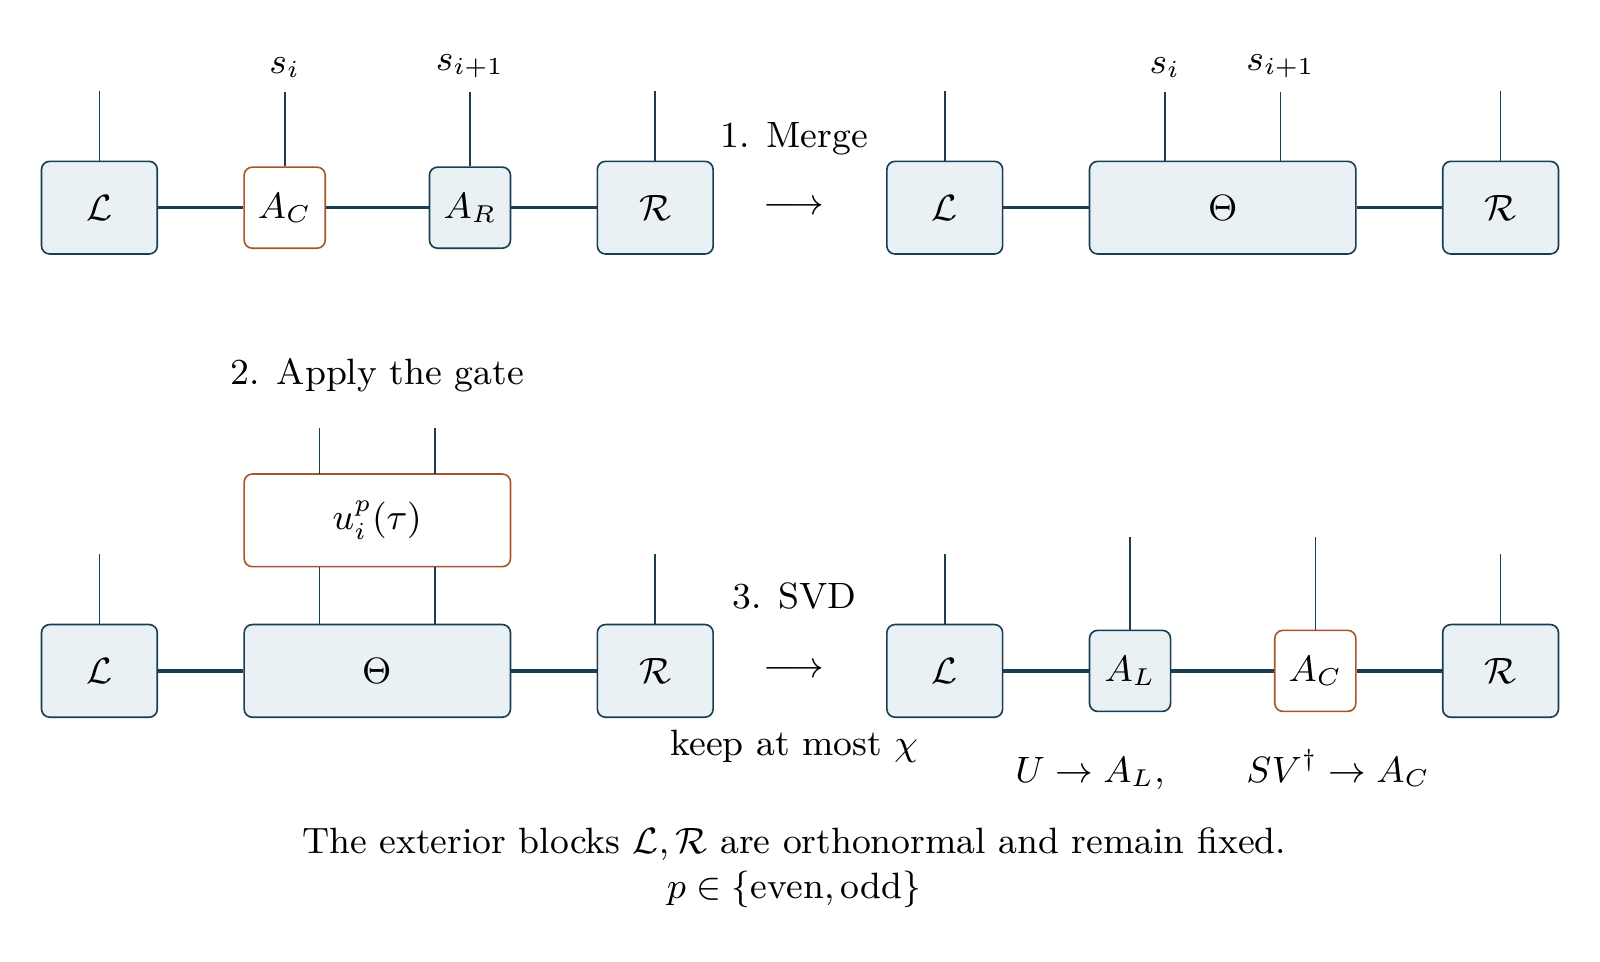

*Merge, apply $u_i^p(\tau)$, then split by SVD, with $p$ indicating an even or odd bond. The exterior canonical blocks remain fixed during this local update.*

In [41]:
def two_site_update(mps, site, u, max_bond):
    theta = np.einsum("sac,tcb->stab", mps[site], mps[site + 1])
    theta = np.einsum("uvst,stab->uvab", u, theta)
    d1, d2, left, right = theta.shape
    matrix = theta.transpose(2, 0, 1, 3).reshape(left * d1, d2 * right)
    U, s, Vh = np.linalg.svd(matrix, full_matrices=False)
    keep = min(max_bond, len(s))
    discarded = np.sum(s[keep:]**2) / np.sum(s**2)
    mps[site] = U[:, :keep].reshape(left, d1, keep).transpose(1, 0, 2)
    remainder = np.einsum("a,ab->ab", s[:keep], Vh[:keep])
    mps[site + 1] = remainder.reshape(keep, d2, right).transpose(1, 0, 2)
    return discarded

### One complete timestep

Begin with the centre at site zero and all later tensors right-canonical. For each of the
three layers, sweep through the bonds from left to right. On a bond belonging to the
current layer, apply its gate with `two_site_update`. On every other bond, use `shift_right`
to move the centre one site without applying a gate. Either operation leaves the centre
in the correct position for the next bond.

After each layer, sweep the centre back to zero with `shift_left`. These are gauge changes,
not additional physical gates. The code makes a fixed number of passes through the chain,
so the cost remains linear in chain length at fixed bond dimension; it does not regauge
the full chain for each gate. The `unitaries` list stores $u_i^{\mathrm{even}}(\delta t/2)$ on even bonds and
$u_i^{\mathrm{odd}}(\delta t)$ on odd bonds; the even unitaries are reused in both outer layers.

Compression can remove norm. With the centre at zero, normalize the state by normalizing
that tensor. The function updates its MPS in place and returns the sum of the local
relative discarded weights for this timestep. That sum is a useful diagnostic, **not the
global infidelity** after many updates.

In [42]:
def tebd_step(mps, unitaries, max_bond):
    discarded = 0.
    for parity in (0, 1, 0):  # Even half, odd full, even half.
        for site in range(len(mps) - 1):
            if site % 2 == parity:
                discarded += two_site_update(mps, site, unitaries[site], max_bond)
            else:
                shift_right(mps, site)
        for site in range(len(mps) - 1, 0, -1):
            shift_left(mps, site)
    mps[0] /= np.linalg.norm(mps[0])
    return discarded

### A six-site quench

Start in $|000000\rangle$, a ground state of the ferromagnetic Ising model at $h=0$.
At $t=0$, switch on the field $h=-0.7$, keeping $J=-1$, and evolve with this fixed Hamiltonian.
This sudden change is a **quench**. Follow the average magnetization
$\overline Z=\langle\sum_i Z_i\rangle/N$ using the MPO sweep.

For this small chain, we also diagonalize the full Hamiltonian once to obtain an exact
reference. This reference calculation uses all $2^N$ amplitudes; the TEBD updates do not.

In [43]:
tebd_n = 6
tebd_J, tebd_h = -1., -0.7
tebd_initial = [np.array([1., 0.]).reshape(2, 1, 1) for _ in range(tebd_n)]
tebd_hamiltonian = ising_mpo(tebd_n, tebd_J, tebd_h)
tebd_magnetization = sum_mpo(np.diag([1., -1.]), tebd_n)

tebd_values, tebd_vectors = np.linalg.eigh(mpo_to_matrix(tebd_hamiltonian))
tebd_initial_vector = mps_to_tensor(tebd_initial).ravel()
tebd_coefficients = np.einsum("ak,a->k", tebd_vectors.conj(), tebd_initial_vector)
tebd_dense_magnetization = mpo_to_matrix(tebd_magnetization) / tebd_n


def exact_tebd_state(time):
    return np.einsum("ak,k,k->a", tebd_vectors, np.exp(-1j * time * tebd_values), tebd_coefficients)

Use $\delta t=0.05$ and evolve to $t=2$. At bond dimension eight, no Schmidt values need
be discarded for six qubits, so this run isolates the Trotter error. The printed energy
change compares the final energy with its initial value; the exact real-time evolution
conserves both the energy and norm.

In [44]:
tebd_dt = 0.05
tebd_steps = 40
tebd_max_bond = 8
tebd_mps = mixed_canonical(tebd_initial, 0)
unitaries = ising_unitaries(tebd_n, tebd_dt, tebd_J, tebd_h)

print(f"{'time':>6} {'TEBD <Z>':>12} {'exact <Z>':>12}")
for step in range(tebd_steps + 1):
    if step % 10 == 0:
        reference = exact_tebd_state(step * tebd_dt)
        exact_z = np.einsum("a,ab,b->", reference.conj(), tebd_dense_magnetization, reference).real
        mean_z = mpo_expectation(tebd_mps, tebd_magnetization) / tebd_n
        print(f"{step * tebd_dt:>6.2f} {mean_z:>12.6f} {exact_z:>12.6f}")
    if step < tebd_steps:
        tebd_step(tebd_mps, unitaries, tebd_max_bond)
print("Final norm:", np.sqrt(mps_norm_squared(tebd_mps)))
print("Energy change:", mpo_expectation(tebd_mps, tebd_hamiltonian) - mpo_expectation(tebd_initial, tebd_hamiltonian))

  time     TEBD <Z>    exact <Z>
  0.00     1.000000     1.000000
  0.50     0.813838     0.813830
  1.00     0.600381     0.600297
  1.50     0.487165     0.487003
  2.00     0.428403     0.428214
Final norm: 1.0000000000000004
Energy change: -0.0002355906005959696


### Separate timestep error from truncation error

There are two independent controls. First fix a sufficiently large bond dimension and
reduce the timestep. Then fix the timestep and increase the bond dimension. At insufficient
bond dimension, reducing the timestep alone need not improve the result.

The first three rows below use $\chi=8$: halving the timestep should reduce the state error
by approximately four. The last two rows use the middle timestep and lower the bond cap, to
compare with the $\chi=8$ row at that same timestep. Using 20, 40 and 80 steps
keeps the final time identical even if you change the duration of the quench.

For the small ED reference, compare full states after removing an irrelevant overall
phase. The discarded-weight column sums local relative losses throughout the evolution;
it is not this state error, nor its square. Norm is restored after each timestep, so a
norm close to one alone does not establish accurate dynamics.

In [45]:
final_time = tebd_steps * tebd_dt
print(f"{'dt':>7} {'max bond':>10} {'state error':>14} {'sum discarded':>16}")
for trial_steps, trial_bond in [(20, 8), (40, 8), (80, 8), (40, 2), (40, 4)]:
    trial_dt = final_time / trial_steps
    trial_mps = mixed_canonical(tebd_initial, 0)
    trial_unitaries = ising_unitaries(tebd_n, trial_dt, tebd_J, tebd_h)
    discarded = 0.
    for step in range(trial_steps):
        discarded += tebd_step(trial_mps, trial_unitaries, trial_bond)
    reference = exact_tebd_state(trial_steps * trial_dt)
    trial_vector = mps_to_tensor(trial_mps).ravel()
    overlap = np.einsum("a,a->", reference.conj(), trial_vector)
    state_error = np.linalg.norm(trial_vector * np.exp(-1j * np.angle(overlap)) - reference)
    print(f"{trial_dt:>7.3f} {trial_bond:>10} {state_error:>14.6e} {discarded:>16.6e}")

     dt   max bond    state error    sum discarded
  0.100          8   2.044633e-03     0.000000e+00
  0.050          8   5.110700e-04     0.000000e+00
  0.025          8   1.277619e-04     0.000000e+00
  0.050          2   4.068495e-01     1.261355e-02
  0.050          4   2.070733e-02     2.741889e-05


**Try it.** Change the bond cap or evolve for longer. As entanglement grows, accurate
simulation generally requires larger bonds. The cost of TEBD is linear in chain length
at fixed bond dimension, but the required bond dimension need not remain small at long times.

An optional connection to ground-state calculations is **imaginary-time evolution**,
$e^{-\tau H}|\psi_0\rangle$, which suppresses higher-energy components when the starting
state overlaps the ground-state sector. Its gates are nonunitary, so normalization and
the canonical gauges must be maintained accordingly. The implementation above is for
real-time unitary evolution.